In [1]:
# importing needed packages
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import os
from scipy import stats
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# read in the cleaned CSV with data from central valley stations
path = 'D:/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
if os.path.exists(path):
    CV_rows = pd.read_csv(path, low_memory = False)
else:
    path = '/Volumes/disk1/Central Valley Fog/cleaned_data_Oct_all_filtered.csv'
    CV_rows = pd.read_csv(path, low_memory = False)

print(CV_rows)

           STATION_ID         STATION                 DATE  year  month  day  \
0         USW00023155  BAKERSFIELD AP  1928-01-01 02:00:00  1928      1    1   
1         USW00023155  BAKERSFIELD AP  1928-01-01 05:00:00  1928      1    1   
2         USW00023155  BAKERSFIELD AP  1928-01-01 08:00:00  1928      1    1   
3         USW00023155  BAKERSFIELD AP  1928-01-01 09:00:00  1928      1    1   
4         USW00023155  BAKERSFIELD AP  1928-01-01 11:00:00  1928      1    1   
...               ...             ...                  ...   ...    ...  ...   
10131269  USW00023202  TRAVIS FLD AFB  2026-09-28 02:55:00  2026      9   28   
10131270  USW00023202  TRAVIS FLD AFB  2026-09-28 03:55:00  2026      9   28   
10131271  USW00023202  TRAVIS FLD AFB  2026-09-28 04:55:00  2026      9   28   
10131272  USW00023202  TRAVIS FLD AFB  2026-09-28 05:55:00  2026      9   28   
10131273  USW00023202  TRAVIS FLD AFB  2026-09-28 06:55:00  2026      9   28   

          hour  minute  LATITUDE  LONGI

In [3]:
# Exclude days from May through September (months 5-9) in CV_fog_rows
CV_rows = CV_rows[~CV_rows['month'].isin([4, 5, 6, 7, 8, 9, 10])]

# # Include days from May through September (months 5-9) in CV_fog_rows
# CV_rows = CV_rows[CV_rows['month'].isin([5, 6, 7, 8, 9])]
# CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

# print to see length after removing May-September
print("CV_rows after removing May-September:", CV_rows.shape)

CV_rows after removing May-September: (4402517, 16)


In [4]:
# # Exclude Hourly wind speeds equal to less than 0.5
# CV_rows = CV_rows[CV_rows["HourlyWindSpeed"] > 0.5]

# print(f"Rows after removing wind speed = 0: {len(CV_rows)}")

In [5]:
# determine the number of rows that have HourlyVisibility values > 16 to check
CV_rows_hv16 = CV_rows[CV_rows['HourlyVisibility'] > 16]

print(f"Number of rows with HourlyVisibility > 16: {len(CV_rows_hv16)}")

Number of rows with HourlyVisibility > 16: 0


In [6]:
# filtering visibility threshold to get rid of nan values
CV_filtered_rows = CV_rows[CV_rows["HourlyVisibility"] < 17]

# print to see the difference
print("CV_rows:", CV_rows.shape)
print("CV_filtered_rows:", CV_filtered_rows.shape)

CV_rows: (4402517, 16)
CV_filtered_rows: (4214230, 16)


In [7]:
CV_rows = CV_rows.drop_duplicates(subset=['STATION', 'year', 'month', 'day', 'hour'])

print("CV_rows after dropping duplicates:", CV_rows.shape)

CV_rows after dropping duplicates: (3379448, 16)


In [8]:
#counting days measured per year per station
filtered_days_year = (
    CV_filtered_rows
    .drop_duplicates(subset=['STATION', 'year', 'month', 'day'])
    .groupby(['STATION', 'year'], as_index=False)
    .size()
    .rename(columns={'size': 'filtered_days'})
    .sort_values(['STATION', 'year'])
)

print(filtered_days_year.head())
print(filtered_days_year.shape)

          STATION  year  filtered_days
0  BAKERSFIELD AP  1928             68
1  BAKERSFIELD AP  1929            120
2  BAKERSFIELD AP  1930             80
3  BAKERSFIELD AP  1931            108
4  BAKERSFIELD AP  1932            152
(1005, 3)


In [9]:
# Only keep station-years with at least 150 filtered_days of data

filtered_days_filtered = filtered_days_year[filtered_days_year['filtered_days'] >= 150]

# filtered_days_filtered = filtered_days_year[filtered_days_year['filtered_days'] >= 365]


# print shape
print(filtered_days_filtered.shape)

# only keep station-years in CV_filtered_rows listed in filtered_days_filtered
CV_filtered_rows = CV_filtered_rows.merge(filtered_days_filtered[['STATION', 'year']], on=['STATION', 'year'], how='inner')
print(CV_filtered_rows.shape)

(889, 3)
(3914961, 16)


In [10]:
# Convert wind-from direction to wind-to direction
CV_filtered_rows['HourlyWindDirection'] = (CV_filtered_rows['HourlyWindDirection'] + 180) % 360
print(CV_filtered_rows.shape)

(3914961, 16)


In [11]:
# #Drop rows with zero values for wind direction
# CV_filtered_rows = CV_filtered_rows[CV_filtered_rows["HourlyWindSpeed"] != 0]

# print(f"Rows after dropping zero wind direction: {len(CV_filtered_rows)}")

In [12]:
# Define the up-valley direction for each station based on latitude
station_up_valley = (
    CV_rows[["STATION", "LATITUDE"]]
    .drop_duplicates("STATION")
    .assign(
        up_valley_direction=lambda df: np.where(
            # stations with latitude greater than or equal to 37.7 have an up-valley direction of 340 degrees
            # stations with latitude less than 37.7 have an up-valley direction of 145 degrees
            df["LATITUDE"] >= 37.7,
            340.0,
            # 160.0,
            145.0
        )
    )
)

# Add the station-specific direction to the station observations
CV_rows = CV_rows.merge(
    station_up_valley[["STATION", "up_valley_direction"]],
    on="STATION",
    how="left"
)

# Add the station-specific up-valley direction to the filtered observations
CV_filtered_rows = CV_filtered_rows.merge(
    station_up_valley[["STATION", "up_valley_direction"]],
    on="STATION",
    how="left"
)

# Check the station-specific directions
display(station_up_valley.sort_values("LATITUDE"))

,STATION,LATITUDE,up_valley_direction
0,BAKERSFIELD AP,35.4342,145.0
3227127,LEMOORE REEVES NAS,36.3333,145.0
2356892,FRESNO YOSEMITE INTL,36.7800,145.0
1669155,CASTLE AFB,37.3833,145.0
8442073,STOCKTON AP,37.8900,340.0
9249840,TRAVIS FLD AFB,38.2667,340.0
5320340,SACRAMENTO AP ASOS,38.5067,340.0
6266950,SACRAMENTO MATHER AFB,38.5667,340.0
7048856,SACRAMENTO MCCLELLAN AFB,38.6667,340.0
7960806,SACRAMENTO METRO AP,38.7006,340.0


In [13]:
# Define the station-specific cross-valley direction based on latitude:
# stations below 38°N use 235°, while stations at or above 38°N use 250°.
station_up_valley["cross_valley_direction"] = np.where(
    station_up_valley["LATITUDE"] < 37.7,
    # 235.0,
    # 250.0
    55.0,
    70.0
)

# Add the cross-valley direction to the filtered observations
CV_filtered_rows = CV_filtered_rows.merge(
    station_up_valley[["STATION", "cross_valley_direction"]],
    on="STATION",
    how="left"
)

# Check the station-specific directions in the filtered observations
display(
    CV_filtered_rows[
        ["STATION", "LATITUDE", "up_valley_direction", "cross_valley_direction"]
    ].sort_values("LATITUDE")
)

,STATION,LATITUDE,up_valley_direction,cross_valley_direction
45,BAKERSFIELD AP,35.4342,145.0,55.0
44,BAKERSFIELD AP,35.4342,145.0,55.0
43,BAKERSFIELD AP,35.4342,145.0,55.0
42,BAKERSFIELD AP,35.4342,145.0,55.0
41,BAKERSFIELD AP,35.4342,145.0,55.0
...,...,...,...,...
2003962,REDDING AP,40.5147,340.0,70.0
2003963,REDDING AP,40.5147,340.0,70.0
2003964,REDDING AP,40.5147,340.0,70.0
2003981,REDDING AP,40.5147,340.0,70.0


In [14]:
# Determine up-valley and cross-valley wind components for CV_filtered_rows
# First make sure wind direction is numeric values
wd_filtered = pd.to_numeric(CV_filtered_rows["HourlyWindDirection"], errors="coerce")

# Wind was converted to wind-toward direction previously no change is not needed

# Compute angle difference of measured wind direction relative to each station's up-valley direction
# We subtract the up-valley direction from the measured wind direction to get the relative angle
# then use deg2rad to convert the angle difference from degrees to radians
delta_along_filtered = np.deg2rad(wd_filtered - CV_filtered_rows["up_valley_direction"])

# Using the angle difference, we compute the wind components 
# Up-valley component: positive = up-valley, negative = down-valley
# # multiply by the wind speed to get the actual wind component
# CV_filtered_rows["up_valley_component"] = np.cos(delta_along_filtered) * CV_filtered_rows["HourlyWindSpeed"]
# use only the angle
CV_filtered_rows["up_valley_component"] = np.cos(delta_along_filtered) 


# Cross-valley component: positive = along cross-valley direction (defined as more eastward)
# negative = opposite cross-valley direction (defined as more westward)
delta_cross_filtered = np.deg2rad(wd_filtered - CV_filtered_rows["cross_valley_direction"])
# # get magnitude
# CV_filtered_rows["cross_valley_component"] = np.cos(delta_cross_filtered) * CV_filtered_rows["HourlyWindSpeed"]
# Use only the angle
CV_filtered_rows["cross_valley_component"] = np.cos(delta_cross_filtered)

# Handle missing/calm winds
# a zero value indicates calm wind
missing_mask_filtered = wd_filtered.isna()
calm_mask_filtered = wd_filtered.eq(0)

# add missing and calm wind handling to the up-valley and cross-valley components
CV_filtered_rows.loc[missing_mask_filtered, ["up_valley_component", "cross_valley_component"]] = np.nan
CV_filtered_rows.loc[calm_mask_filtered, ["up_valley_component", "cross_valley_component"]] = 0.0

# Quick check
display(
    CV_filtered_rows[
        ["STATION", "HourlyWindDirection", "HourlyWindSpeed", "up_valley_direction",
         "cross_valley_direction", "up_valley_component", "cross_valley_component"]
    ].head(-10)
)

,STATION,HourlyWindDirection,HourlyWindSpeed,up_valley_direction,cross_valley_direction,up_valley_component,cross_valley_component
0,BAKERSFIELD AP,45.0,1.8,145.0,55.0,-0.173648,0.984808
1,BAKERSFIELD AP,158.0,3.6,145.0,55.0,0.974370,-0.224951
2,BAKERSFIELD AP,45.0,2.3,145.0,55.0,-0.173648,0.984808
3,BAKERSFIELD AP,180.0,2.3,145.0,55.0,0.819152,-0.573576
4,BAKERSFIELD AP,135.0,1.8,145.0,55.0,0.984808,0.173648
...,...,...,...,...,...,...,...
3914946,TRAVIS FLD AFB,200.0,6.2,340.0,70.0,-0.766044,-0.642788
3914947,TRAVIS FLD AFB,220.0,5.1,340.0,70.0,-0.500000,-0.866025
3914948,TRAVIS FLD AFB,210.0,5.7,340.0,70.0,-0.642788,-0.766044
3914949,TRAVIS FLD AFB,220.0,4.6,340.0,70.0,-0.500000,-0.866025


In [15]:
# Check calm winds
#  Display observations with calm winds, represented by wind direction = 0
calm_wind_rows = CV_filtered_rows[
    CV_filtered_rows["HourlyWindDirection"].eq(0)
]

display(calm_wind_rows)

,STATION_ID,STATION,DATE,year,month,day,hour,minute,LATITUDE,LONGITUDE,HourlyDryBulbTemperature,HourlyDewPointTemperature,HourlyWindDirection,HourlyWindSpeed,HourlyPrecipitation,HourlyVisibility,up_valley_direction,cross_valley_direction,up_valley_component,cross_valley_component
17,USW00023155,BAKERSFIELD AP,1932-01-01 18:00:00,1932,1,1,18,0,35.4342,-119.0553,11.1,5.6,0.0,2.7,0.0,16.000,145.0,55.0,0.0,0.0
31,USW00023155,BAKERSFIELD AP,1932-01-02 08:00:00,1932,1,2,8,0,35.4342,-119.0553,7.2,4.4,0.0,2.3,0.0,16.000,145.0,55.0,0.0,0.0
35,USW00023155,BAKERSFIELD AP,1932-01-02 12:00:00,1932,1,2,12,0,35.4342,-119.0553,11.1,4.4,0.0,1.8,0.0,16.000,145.0,55.0,0.0,0.0
56,USW00023155,BAKERSFIELD AP,1932-01-03 09:00:00,1932,1,3,9,0,35.4342,-119.0553,6.1,5.0,0.0,1.4,0.0,6.400,145.0,55.0,0.0,0.0
128,USW00023155,BAKERSFIELD AP,1932-01-06 10:00:00,1932,1,6,10,0,35.4342,-119.0553,7.8,2.8,0.0,0.9,0.0,16.000,145.0,55.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3914720,USW00023202,TRAVIS FLD AFB,2025-12-26 14:55:00,2025,12,26,14,55,38.2667,-121.9333,14.9,7.9,0.0,8.8,0.0,16.000,340.0,70.0,0.0,0.0
3914723,USW00023202,TRAVIS FLD AFB,2025-12-26 16:07:00,2025,12,26,16,7,38.2667,-121.9333,12.0,9.0,0.0,8.8,0.0,14.484,340.0,70.0,0.0,0.0
3914725,USW00023202,TRAVIS FLD AFB,2025-12-26 16:52:00,2025,12,26,16,52,38.2667,-121.9333,13.0,9.0,0.0,5.1,0.0,16.000,340.0,70.0,0.0,0.0
3914726,USW00023202,TRAVIS FLD AFB,2025-12-26 16:55:00,2025,12,26,16,55,38.2667,-121.9333,12.6,9.2,0.0,5.7,0.2,16.000,340.0,70.0,0.0,0.0


In [16]:
# Determine annual average up-valley and cross-valley wind magnitude by station-year
# Here "magnitude" refers to the mean signed wind component along each station-specific axis.

# Use the station-specific axes if they are already defined; otherwise create them
if "station_up_valley" not in globals():
    station_up_valley = (
        CV_rows[["STATION", "LATITUDE"]]
        .drop_duplicates("STATION")
        .assign(
            up_valley_direction=lambda df: np.where(df["LATITUDE"] >= 37.7, 340.0, 145.0),
            cross_valley_direction=lambda df: np.where(df["LATITUDE"] >= 37.7, 70.0, 55.0),
        )
    )

# Aggregate the mean up-valley and cross-valley wind components by station-year
annual_avg_wind = (
    CV_filtered_rows[
        ["STATION", "year", "up_valley_component", "cross_valley_component"]
    ]
    .dropna()
    .groupby(["STATION", "year"], as_index=False)
    .agg(
        mean_up_valley_component=("up_valley_component", "mean"),
        mean_cross_valley_component=("cross_valley_component", "mean"),
        n_obs=("up_valley_component", "size"),
    )
    .sort_values(["STATION", "year"])
    .reset_index(drop=True)
)

# Optional: attach latitude for geographic context
station_lat = (
    CV_filtered_rows.groupby("STATION", as_index=False)["LATITUDE"]
    .median()
    .rename(columns={"LATITUDE": "latitude"})
)

annual_avg_wind = annual_avg_wind.merge(station_lat, on="STATION", how="left")

print(f"Rows in annual_avg_wind: {len(annual_avg_wind)}")
display(annual_avg_wind.head(10))

Rows in annual_avg_wind: 889


,STATION,year,mean_up_valley_component,mean_cross_valley_component,n_obs,latitude
0,BAKERSFIELD AP,1932,0.072577,-0.222804,3449,35.4342
1,BAKERSFIELD AP,1933,0.093292,-0.242457,3445,35.4342
2,BAKERSFIELD AP,1934,0.159961,-0.158812,3503,35.4342
3,BAKERSFIELD AP,1935,0.173850,-0.198303,3508,35.4342
4,BAKERSFIELD AP,1936,0.122704,-0.228974,3583,35.4342
5,BAKERSFIELD AP,1937,0.103092,-0.227931,3560,35.4342
6,BAKERSFIELD AP,1938,0.080970,-0.180013,3500,35.4342
7,BAKERSFIELD AP,1939,0.060477,-0.235126,3505,35.4342
8,BAKERSFIELD AP,1942,0.125056,-0.192959,3543,35.4342
9,BAKERSFIELD AP,1943,0.044030,-0.224356,3516,35.4342


Total station-component regressions: 26
Significant trends (p < 0.05): 14


,STATION,component,start_year,end_year,n_years,slope_per_year,slope_per_decade,intercept,r_squared,p_value
0,SACRAMENTO AP ASOS,cross_valley,1932,2025,87,0.001708,0.017081,-3.330293,0.555404,1.253994e-16
1,BAKERSFIELD AP,cross_valley,1932,2025,92,0.001449,0.014490,-3.023372,0.501834,2.822156e-15
2,SACRAMENTO MCCLELLAN AFB,cross_valley,1940,2025,67,0.001752,0.017521,-3.515148,0.557515,4.049287e-13
3,BEALE AFB,cross_valley,1960,2025,50,-0.001723,-0.017232,3.318416,0.596078,5.209971e-11
4,LEMOORE REEVES NAS,cross_valley,1962,2025,50,0.001821,0.018215,-3.616093,0.514671,4.574101e-09
5,FRESNO YOSEMITE INTL,cross_valley,1942,2025,79,0.001073,0.010731,-2.237365,0.239577,4.700880e-06
6,CASTLE AFB,cross_valley,1942,2022,61,0.000879,0.008793,-1.816219,0.133847,3.737343e-03
7,SACRAMENTO MATHER AFB,cross_valley,1942,2025,71,0.000492,0.004920,-1.027388,0.095198,8.847906e-03
8,REDDING AP,cross_valley,1974,2025,52,0.001134,0.011337,-2.261386,0.106742,1.807993e-02
9,SACRAMENTO METRO AP,cross_valley,1973,2025,53,0.000644,0.006442,-1.227790,0.080234,3.985389e-02


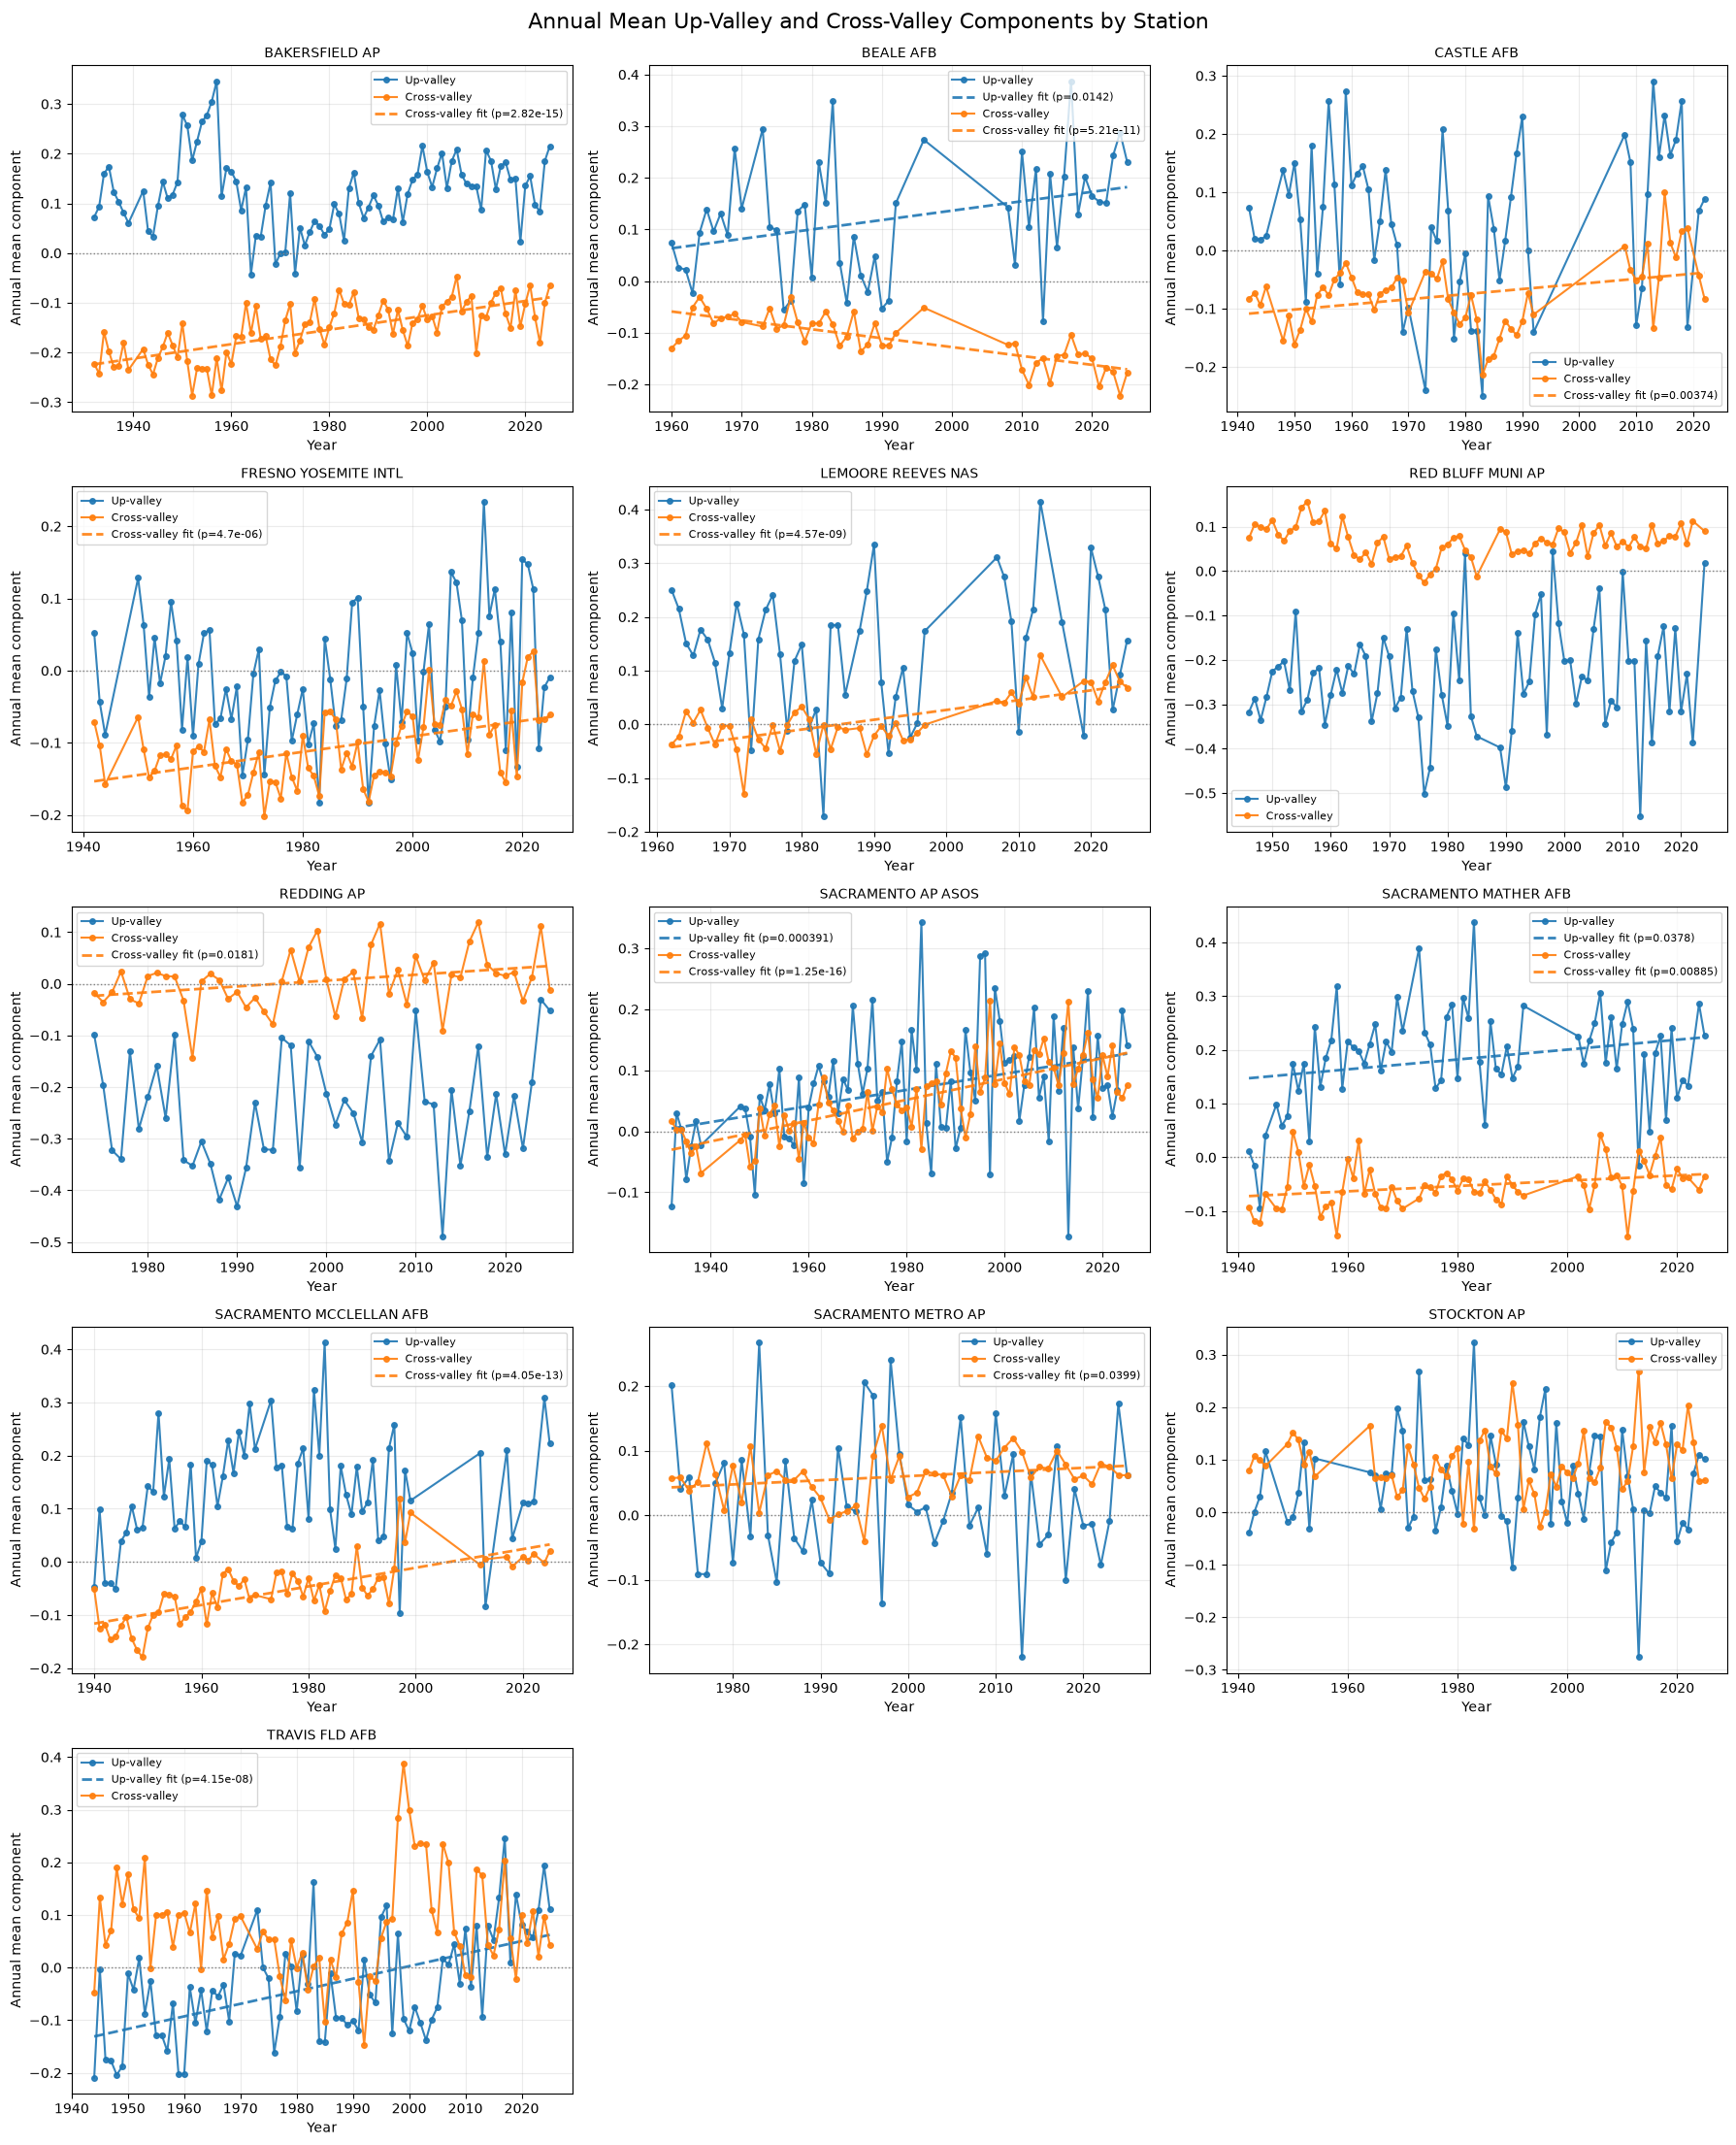

In [17]:
# Trend analysis of annual mean up-valley and cross-valley components by station
# Only plot regression lines for statistically significant trends (p < 0.05)

trend_rows = []

for station, g in annual_avg_wind.groupby("STATION"):
    for component, value_col in [
        ("up_valley", "mean_up_valley_component"),
        ("cross_valley", "mean_cross_valley_component"),
    ]:
        d = g[["year", value_col]].dropna()

        if d.empty or d["year"].nunique() < 3 or d[value_col].nunique() < 2:
            continue

        fit = stats.linregress(d["year"].to_numpy(), d[value_col].to_numpy())

        trend_rows.append({
            "STATION": station,
            "component": component,
            "start_year": int(d["year"].min()),
            "end_year": int(d["year"].max()),
            "n_years": int(d["year"].nunique()),
            "slope_per_year": fit.slope,
            "slope_per_decade": fit.slope * 10,
            "intercept": fit.intercept,
            "r_squared": fit.rvalue ** 2,
            "p_value": fit.pvalue,
        })

trend_df = pd.DataFrame(trend_rows).sort_values(["STATION", "component"]).reset_index(drop=True)
sig_trends = trend_df[trend_df["p_value"] < 0.05].copy()

print(f"Total station-component regressions: {len(trend_df)}")
print(f"Significant trends (p < 0.05): {len(sig_trends)}")
display(sig_trends.sort_values(["component", "p_value"]).reset_index(drop=True))

stations = sorted(annual_avg_wind["STATION"].unique())
ncols = 3
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows), squeeze=False)
axes = axes.ravel()

for ax, station in zip(axes, stations):
    d = annual_avg_wind[annual_avg_wind["STATION"] == station].sort_values("year")

    for component, value_col, color, label in [
        ("up_valley", "mean_up_valley_component", "tab:blue", "Up-valley"),
        ("cross_valley", "mean_cross_valley_component", "tab:orange", "Cross-valley"),
    ]:
        ax.plot(
            d["year"],
            d[value_col],
            marker="o",
            markersize=4,
            linewidth=1.5,
            color=color,
            label=label,
            alpha=0.9,
        )

        result = trend_df[
            (trend_df["STATION"] == station) &
            (trend_df["component"] == component)
        ]

        if not result.empty and result.iloc[0]["p_value"] < 0.05:
            fit = result.iloc[0]
            fitted = fit["intercept"] + fit["slope_per_year"] * d["year"]
            ax.plot(
                d["year"],
                fitted,
                color=color,
                linestyle="--",
                linewidth=2,
                alpha=0.9,
                label=f"{label} fit (p={fit['p_value']:.3g})"
            )

    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.set_title(station, fontsize=10)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual mean component")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8, loc="best")

for ax in axes[len(stations):]:
    ax.remove()

fig.suptitle("Annual Mean Up-Valley and Cross-Valley Components by Station\n", fontsize=16)
plt.tight_layout()
plt.show()

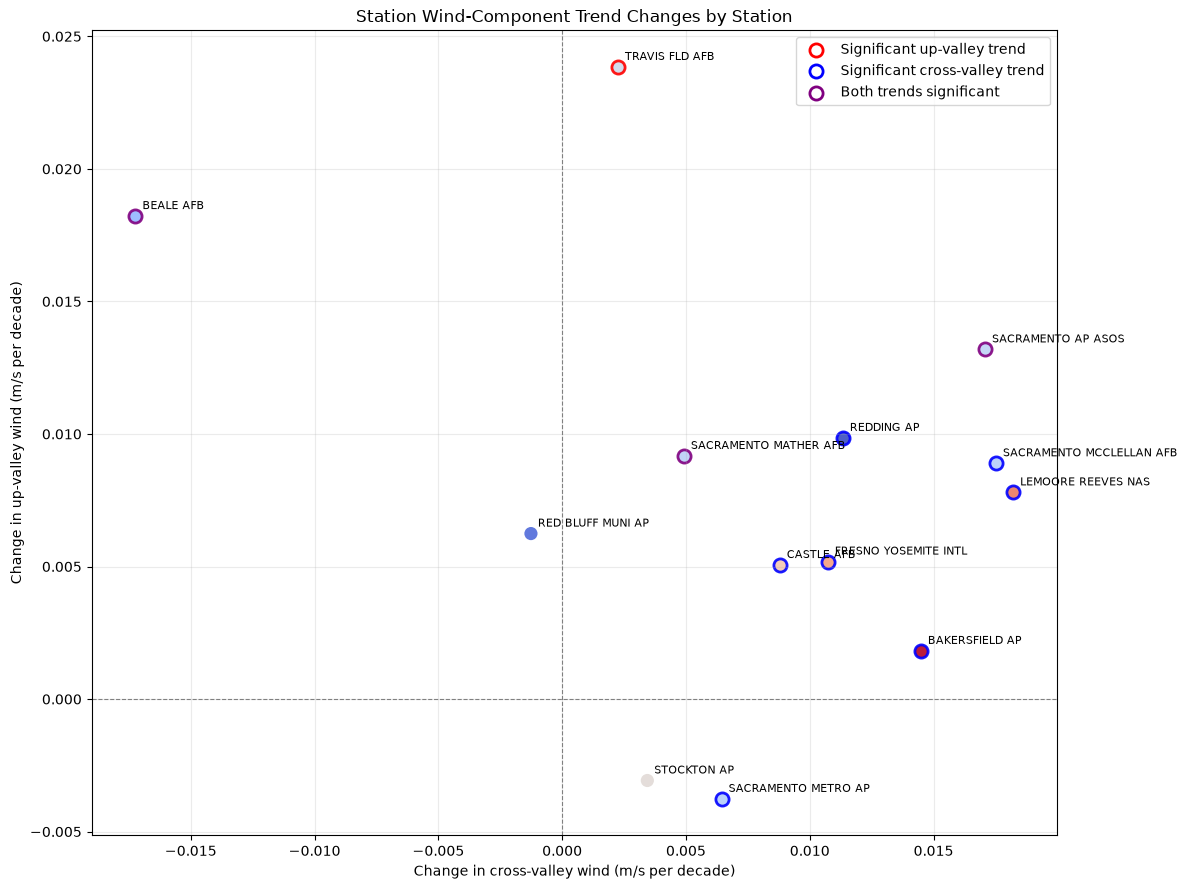

In [18]:
# Plot each station's change in up-valley wind vs. change in cross-valley wind
# Red outline = significant up-valley trend
# Blue outline = significant cross-valley trend
# Purple outline = both significant

slope_data = (
    trend_df
    .pivot(index="STATION", columns="component", values=["slope_per_decade", "p_value"])
    .dropna()
)

slope_data.columns = [
    f"{metric}_{component}"
    for metric, component in slope_data.columns
]

plot_data = (
    slope_data
    .reset_index()
    .merge(station_lat, on="STATION", how="left")
    .dropna(subset=["latitude"])
)

lat_min = plot_data["latitude"].min()
lat_max = plot_data["latitude"].max()
lat_range = lat_max - lat_min if lat_max != lat_min else 1

fig, ax = plt.subplots(figsize=(12, 9))

for _, row in plot_data.iterrows():
    station = row["STATION"]
    x = row["slope_per_decade_cross_valley"]
    y = row["slope_per_decade_up_valley"]

    sig_up = row["p_value_up_valley"] < 0.05
    sig_cross = row["p_value_cross_valley"] < 0.05

    if sig_up and sig_cross:
        outline_color = "purple"
    elif sig_up:
        outline_color = "red"
    elif sig_cross:
        outline_color = "blue"
    else:
        outline_color = "none"

    point_color = plt.cm.coolwarm_r((row["latitude"] - lat_min) / lat_range)

    ax.scatter(
        x,
        y,
        color=point_color,
        edgecolors=outline_color,
        linewidths=2 if outline_color != "none" else 0.8,
        s=90,
        alpha=0.9,
    )

    ax.annotate(
        station,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

for color, label in [
    ("red", "Significant up-valley trend"),
    ("blue", "Significant cross-valley trend"),
    ("purple", "Both trends significant"),
]:
    ax.scatter(
        [], [],
        color="white",
        edgecolors=color,
        linewidths=2,
        s=90,
        label=label,
    )

ax.set_xlabel("Change in cross-valley wind (m/s per decade)")
ax.set_ylabel("Change in up-valley wind (m/s per decade)")
ax.set_title("Station Wind-Component Trend Changes by Station")
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

Total station-component regressions: 26
Significant trends (p < 0.05): 13


,STATION,component,start_year,end_year,n_years,slope_per_year,slope_per_decade,intercept,r_squared,p_value
0,LEMOORE REEVES NAS,cross_valley,1980,2025,32,0.002696,0.026960,-5.371317,0.680668,6.320782e-09
1,BEALE AFB,cross_valley,1980,2025,32,-0.002135,-0.021354,4.145862,0.578771,4.333935e-07
2,CASTLE AFB,cross_valley,1980,2022,27,0.003885,0.038855,-7.848141,0.578118,4.182453e-06
3,FRESNO YOSEMITE INTL,cross_valley,1980,2025,46,0.001856,0.018562,-3.804278,0.227554,8.027258e-04
4,SACRAMENTO MCCLELLAN AFB,cross_valley,1980,2025,29,0.001525,0.015250,-3.064206,0.222119,9.859346e-03
5,RED BLUFF MUNI AP,cross_valley,1980,2024,41,0.000770,0.007696,-1.473817,0.152040,1.173043e-02
6,SACRAMENTO AP ASOS,cross_valley,1980,2025,46,0.001293,0.012933,-2.497433,0.123175,1.678140e-02
7,SACRAMENTO METRO AP,cross_valley,1980,2025,46,0.000890,0.008903,-1.722110,0.110551,2.396611e-02
8,TRAVIS FLD AFB,up_valley,1980,2025,46,0.004136,0.041358,-8.283359,0.299385,8.322978e-05
9,BAKERSFIELD AP,up_valley,1980,2025,46,0.001635,0.016353,-3.144990,0.189242,2.517087e-03


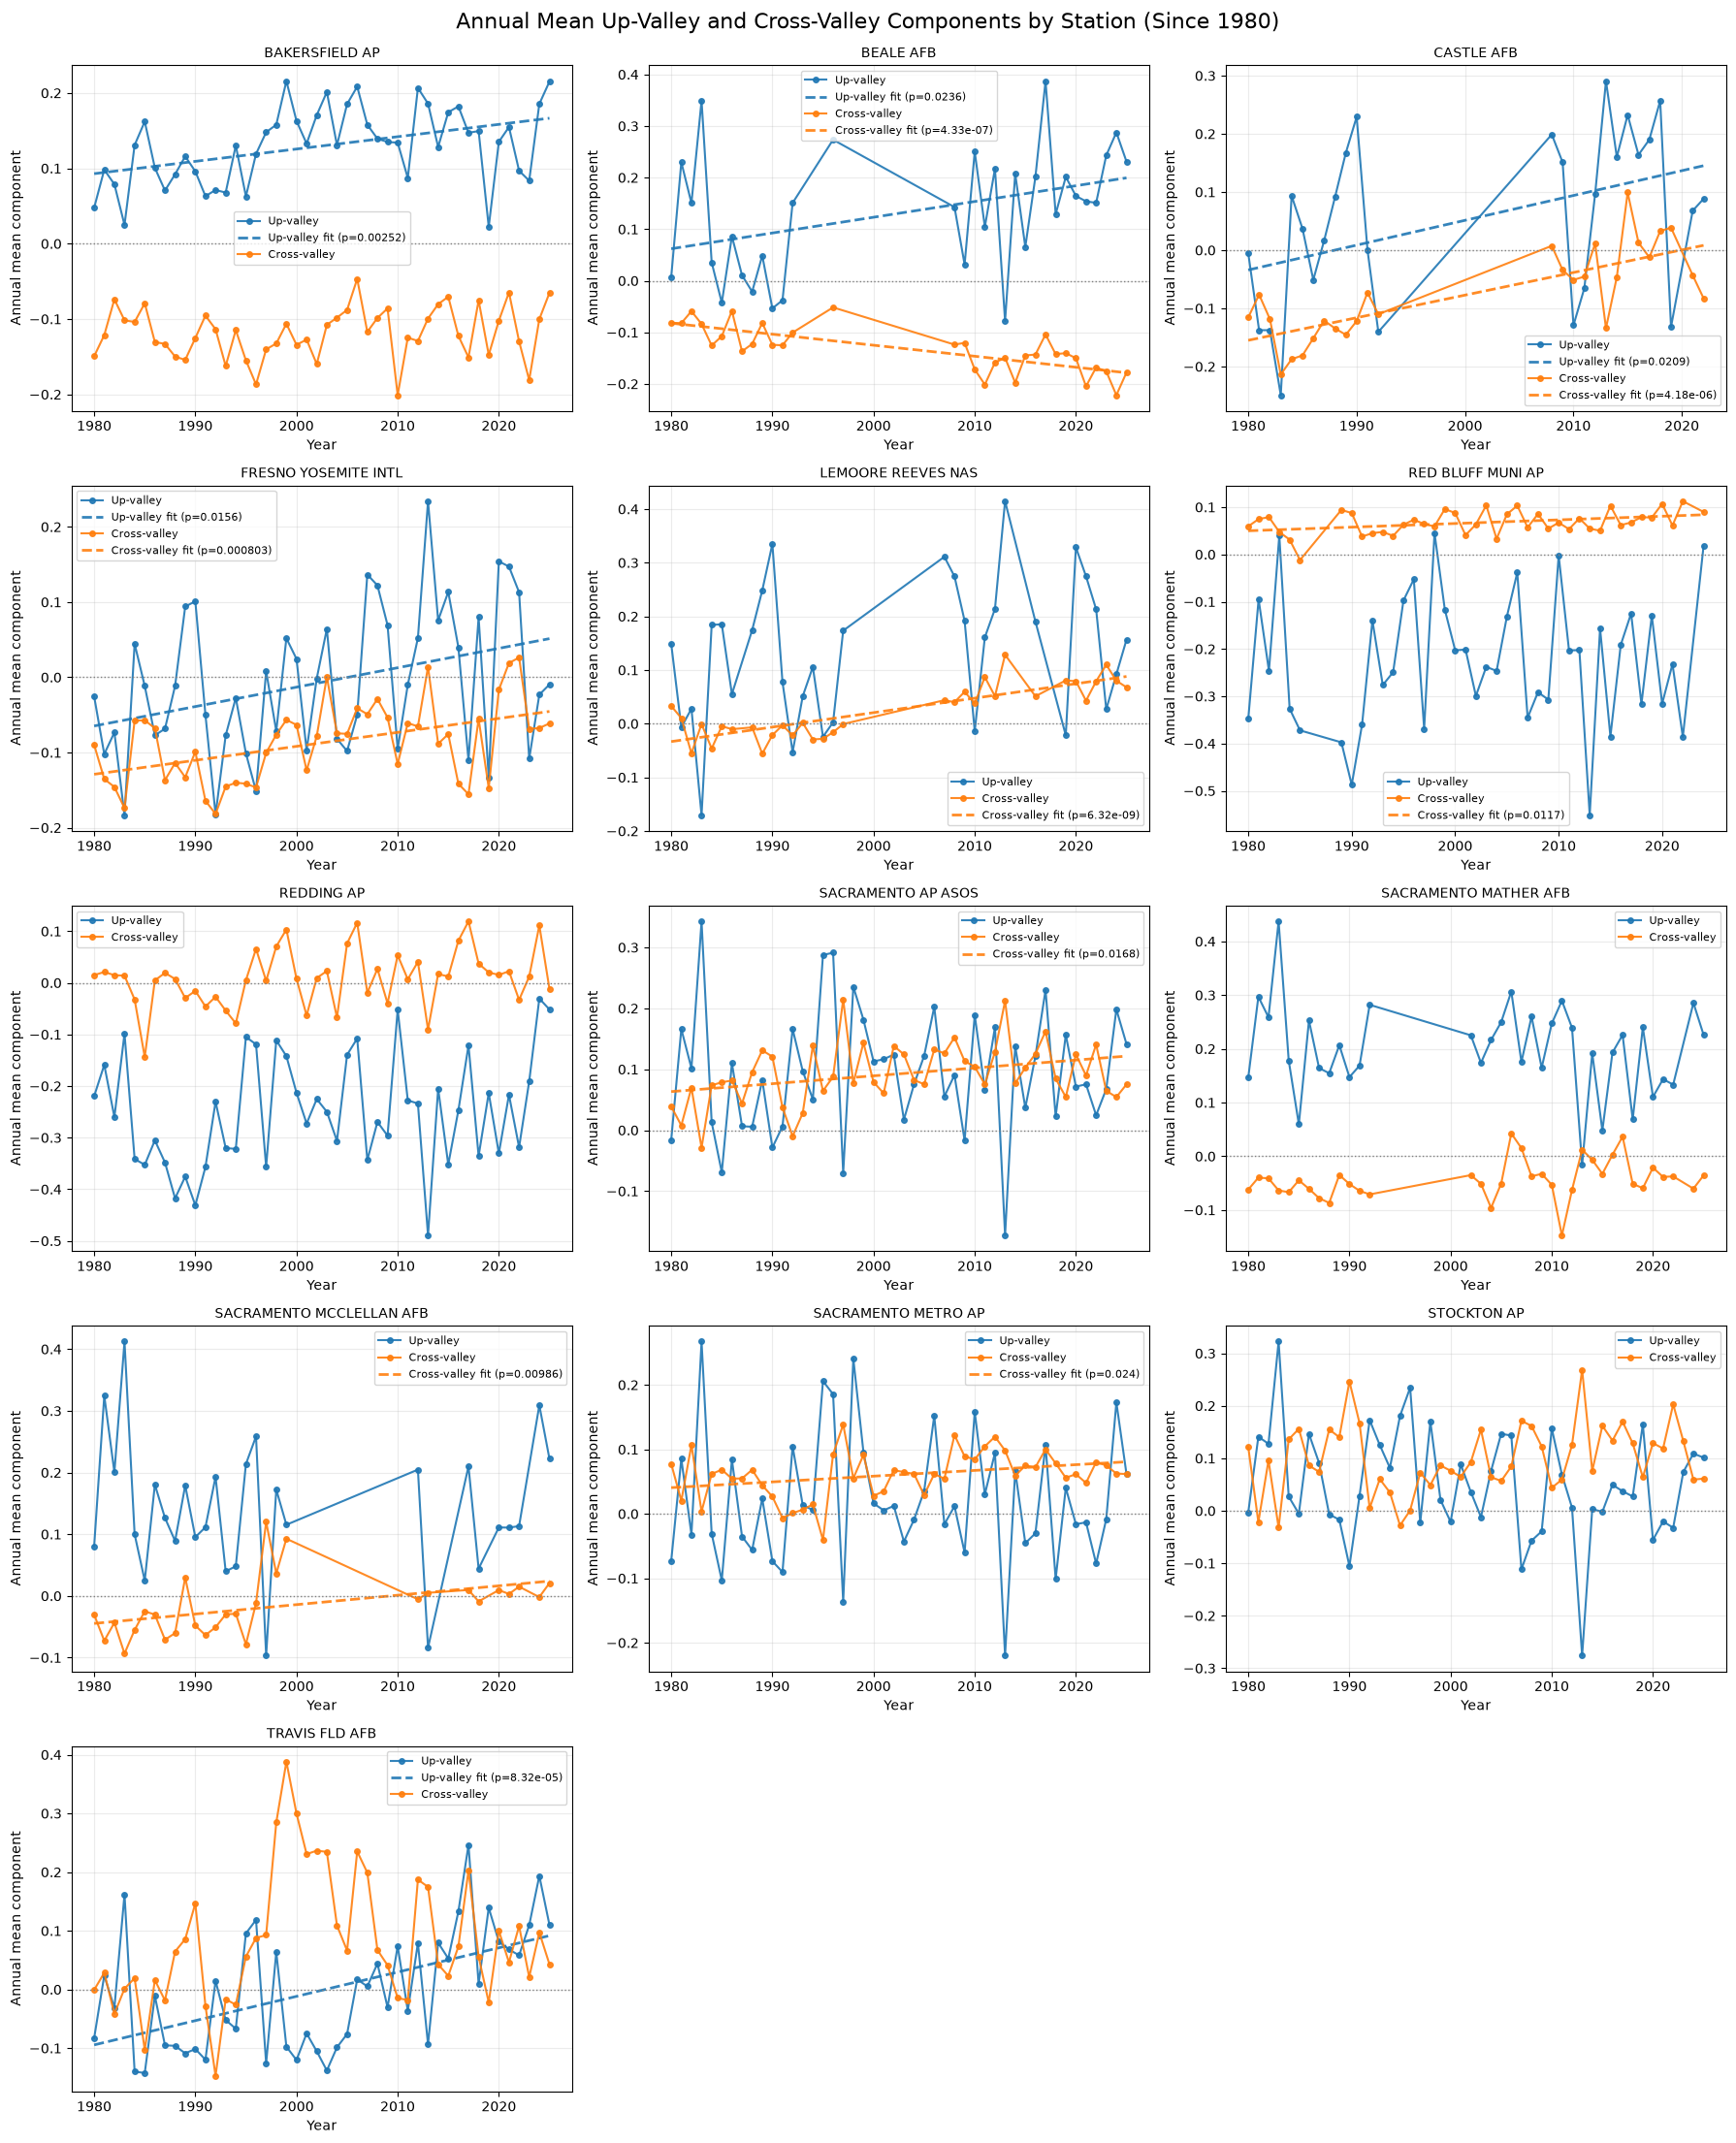

In [19]:
# Trend analysis of annual mean up-valley and cross-valley components by station
# Only plot regression lines for statistically significant trends (p < 0.05)
# Use only years since 1980

trend_rows_1980 = []
annual_avg_wind_1980 = annual_avg_wind[annual_avg_wind["year"] >= 1980]

for station, g in annual_avg_wind_1980.groupby("STATION"):
    for component, value_col in [
        ("up_valley", "mean_up_valley_component"),
        ("cross_valley", "mean_cross_valley_component"),
    ]:
        d = g[["year", value_col]].dropna()

        if d.empty or d["year"].nunique() < 3 or d[value_col].nunique() < 2:
            continue

        fit = stats.linregress(d["year"].to_numpy(), d[value_col].to_numpy())

        trend_rows_1980.append({
            "STATION": station,
            "component": component,
            "start_year": int(d["year"].min()),
            "end_year": int(d["year"].max()),
            "n_years": int(d["year"].nunique()),
            "slope_per_year": fit.slope,
            "slope_per_decade": fit.slope * 10,
            "intercept": fit.intercept,
            "r_squared": fit.rvalue ** 2,
            "p_value": fit.pvalue,
        })

trend_df_1980 = pd.DataFrame(trend_rows_1980).sort_values(["STATION", "component"]).reset_index(drop=True)
sig_trends = trend_df_1980[trend_df_1980["p_value"] < 0.05].copy()

print(f"Total station-component regressions: {len(trend_df_1980)}")
print(f"Significant trends (p < 0.05): {len(sig_trends)}")
display(sig_trends.sort_values(["component", "p_value"]).reset_index(drop=True))

stations = sorted(annual_avg_wind_1980["STATION"].unique())
ncols = 3
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows), squeeze=False)
axes = axes.ravel()

for ax, station in zip(axes, stations):
    d = annual_avg_wind_1980[annual_avg_wind_1980["STATION"] == station].sort_values("year")

    for component, value_col, color, label in [
        ("up_valley", "mean_up_valley_component", "tab:blue", "Up-valley"),
        ("cross_valley", "mean_cross_valley_component", "tab:orange", "Cross-valley"),
    ]:
        ax.plot(
            d["year"],
            d[value_col],
            marker="o",
            markersize=4,
            linewidth=1.5,
            color=color,
            label=label,
            alpha=0.9,
        )

        result = trend_df_1980[
            (trend_df_1980["STATION"] == station) &
            (trend_df_1980["component"] == component)
        ]

        if not result.empty and result.iloc[0]["p_value"] < 0.05:
            fit = result.iloc[0]
            fitted = fit["intercept"] + fit["slope_per_year"] * d["year"]
            ax.plot(
                d["year"],
                fitted,
                color=color,
                linestyle="--",
                linewidth=2,
                alpha=0.9,
                label=f"{label} fit (p={fit['p_value']:.3g})"
            )

    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.set_title(station, fontsize=10)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual mean component")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8, loc="best")

for ax in axes[len(stations):]:
    ax.remove()

fig.suptitle("Annual Mean Up-Valley and Cross-Valley Components by Station (Since 1980)\n", fontsize=16)
plt.tight_layout()
plt.show()


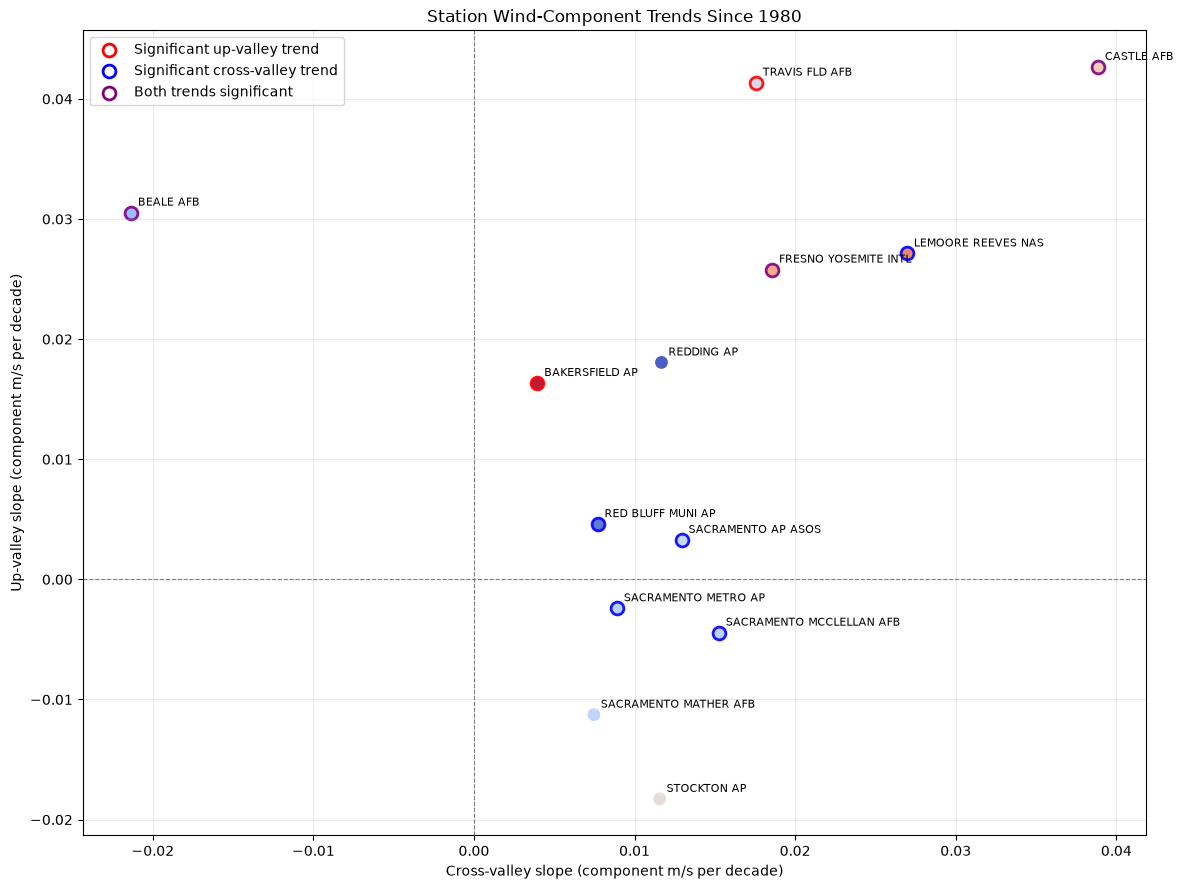

In [20]:
# Plot 1980 onward station trends with significance shown by outline color:
# red = significant up-valley trend
# blue = significant cross-valley trend
# purple = both significant

slope_data_1980 = (
    trend_df_1980
    .pivot(index="STATION", columns="component", values=["slope_per_decade", "p_value"])
    .dropna()
)

slope_data_1980.columns = [
    f"{metric}_{component}"
    for metric, component in slope_data_1980.columns
]

plot_data_1980 = (
    slope_data_1980
    .reset_index()
    .merge(station_lat, on="STATION", how="left")
    .dropna(subset=["latitude"])
)

fig, ax = plt.subplots(figsize=(12, 9))

for _, row in plot_data_1980.iterrows():
    station = row["STATION"]
    color = plt.cm.coolwarm_r((row["latitude"] - lat_min) / lat_range)

    significant_up = row["p_value_up_valley"] < 0.05
    significant_cross = row["p_value_cross_valley"] < 0.05

    if significant_up and significant_cross:
        outline_color = "purple"
    elif significant_up:
        outline_color = "red"
    elif significant_cross:
        outline_color = "blue"
    else:
        outline_color = "none"

    ax.scatter(
        row["slope_per_decade_cross_valley"],
        row["slope_per_decade_up_valley"],
        color=color,
        marker="o",
        s=85,
        edgecolors=outline_color,
        linewidths=2 if outline_color != "none" else 0.8,
        alpha=0.9,
    )

    ax.annotate(
        station,
        (
            row["slope_per_decade_cross_valley"],
            row["slope_per_decade_up_valley"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

# Significance legend
for color, label in [
    ("red", "Significant up-valley trend"),
    ("blue", "Significant cross-valley trend"),
    ("purple", "Both trends significant"),
]:
    ax.scatter(
        [], [], color="white", edgecolors=color, marker="o",
        s=85, linewidths=2, label=label
    )

ax.set_xlabel("Cross-valley slope (component m/s per decade)")
ax.set_ylabel("Up-valley slope (component m/s per decade)")
ax.set_title("Station Wind-Component Trends Since 1980")
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

In [21]:
# Identify individual fog events as consecutive hourly fog observations (HourlyVisibility < 1)
fog_rows = CV_filtered_rows[(CV_filtered_rows["HourlyVisibility"] < 1)
                            & (CV_filtered_rows["HourlyPrecipitation"] < 0.03)].copy()

# Construct timestamps from year, month, day, and hour
fog_rows["timestamp"] = (
    pd.to_datetime(fog_rows[["year", "month", "day"]])
    + pd.to_timedelta(fog_rows["hour"], unit="h")
)

fog_rows = fog_rows.dropna(subset=["timestamp"]).sort_values(["STATION", "timestamp"])

# Consecutive hourly observations belong to the same event
time_gap = fog_rows.groupby("STATION")["timestamp"].diff()
fog_rows["new_event"] = time_gap.isna() | (time_gap > pd.Timedelta(hours=1))
fog_rows["event_number"] = fog_rows.groupby("STATION")["new_event"].cumsum().astype(int)

# Aggregate events and calculate mean wind-direction components
fog_events = (
    fog_rows
    .groupby(["STATION", "event_number"], as_index=False)
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        n_observations=("timestamp", "size"),
        min_visibility=("HourlyVisibility", "min"),
        mean_visibility=("HourlyVisibility", "mean"),
        mean_up_valley_component=("up_valley_component", "mean"),
        mean_cross_valley_component=("cross_valley_component", "mean"),
        up_valley_direction=("up_valley_direction", "first"),
        cross_valley_direction=("cross_valley_direction", "first"),
    )
)

# Calculate duration in hours
fog_events["duration_hours"] = (
    (fog_events["end_time"] - fog_events["start_time"]).dt.total_seconds() / 3600 + 1
)

# Calculate average wind direction from mean components for each event
fog_events["avg_wind_direction_deg"] = np.mod(
    np.rad2deg(
        np.arctan2(
            fog_events["mean_cross_valley_component"],
            fog_events["mean_up_valley_component"]
        )
    ) + fog_events["up_valley_direction"],
    360.0
)

fog_events = fog_events.sort_values(["STATION", "start_time"]).reset_index(drop=True)

print(f"Total fog events: {len(fog_events)}")
display(fog_events.head(10))

Total fog events: 36284


,STATION,event_number,start_time,end_time,n_observations,min_visibility,mean_visibility,mean_up_valley_component,mean_cross_valley_component,up_valley_direction,cross_valley_direction,duration_hours,avg_wind_direction_deg
0,BAKERSFIELD AP,1,1932-01-01 08:00:00,1932-01-01 09:00:00,2,0.0,0.000000,-0.579228,0.405580,145.0,55.0,2.0,290.000000
1,BAKERSFIELD AP,2,1932-01-04 09:00:00,1932-01-04 09:00:00,1,0.0,0.000000,-0.984808,-0.173648,145.0,55.0,1.0,335.000000
2,BAKERSFIELD AP,3,1932-01-08 18:00:00,1932-01-08 19:00:00,2,0.0,0.000000,0.984808,0.173648,145.0,55.0,2.0,155.000000
3,BAKERSFIELD AP,4,1932-01-09 04:00:00,1932-01-09 09:00:00,6,0.0,0.366667,-0.592386,-0.537814,145.0,55.0,6.0,7.235610
4,BAKERSFIELD AP,5,1932-01-09 19:00:00,1932-01-09 19:00:00,1,0.0,0.000000,0.984808,0.173648,145.0,55.0,1.0,155.000000
5,BAKERSFIELD AP,6,1932-01-09 21:00:00,1932-01-10 08:00:00,12,0.0,0.283333,0.462521,0.455081,145.0,55.0,12.0,189.535456
6,BAKERSFIELD AP,7,1932-01-19 03:00:00,1932-01-19 04:00:00,2,0.2,0.500000,-0.779192,-0.496400,145.0,55.0,2.0,357.500000
7,BAKERSFIELD AP,8,1932-01-20 09:00:00,1932-01-20 09:00:00,1,0.8,0.800000,-0.984808,-0.173648,145.0,55.0,1.0,335.000000
8,BAKERSFIELD AP,9,1932-01-23 08:00:00,1932-01-23 09:00:00,2,0.0,0.000000,-0.286788,-0.409576,145.0,55.0,2.0,20.000000
9,BAKERSFIELD AP,10,1932-01-27 09:00:00,1932-01-27 09:00:00,1,0.2,0.200000,0.984808,0.173648,145.0,55.0,1.0,155.000000


,STATION,component,start_year,end_year,n_years,slope_per_year,slope_per_decade,r_squared,p_value,significant
9,LEMOORE REEVES NAS,cross_valley,1962,2025,50,0.002723,0.027227,0.315604,0.000022,True
3,BEALE AFB,cross_valley,1960,2025,50,-0.002921,-0.029207,0.271471,0.000105,True
11,RED BLUFF MUNI AP,cross_valley,1946,2024,74,0.002588,0.025881,0.171727,0.000242,True
25,TRAVIS FLD AFB,cross_valley,1944,2025,80,0.003219,0.032189,0.127407,0.001154,True
15,SACRAMENTO AP ASOS,cross_valley,1932,2025,87,0.001281,0.012809,0.077353,0.009098,True
17,SACRAMENTO MATHER AFB,cross_valley,1942,2025,71,-0.001115,-0.011147,0.043248,0.081807,False
19,SACRAMENTO MCCLELLAN AFB,cross_valley,1940,2025,67,0.000891,0.008915,0.035039,0.129317,False
23,STOCKTON AP,cross_valley,1942,2025,72,0.000878,0.008775,0.026193,0.174398,False
7,FRESNO YOSEMITE INTL,cross_valley,1942,2025,79,0.000622,0.006216,0.013838,0.301840,False
5,CASTLE AFB,cross_valley,1942,2022,61,-0.000645,-0.006455,0.017230,0.313276,False


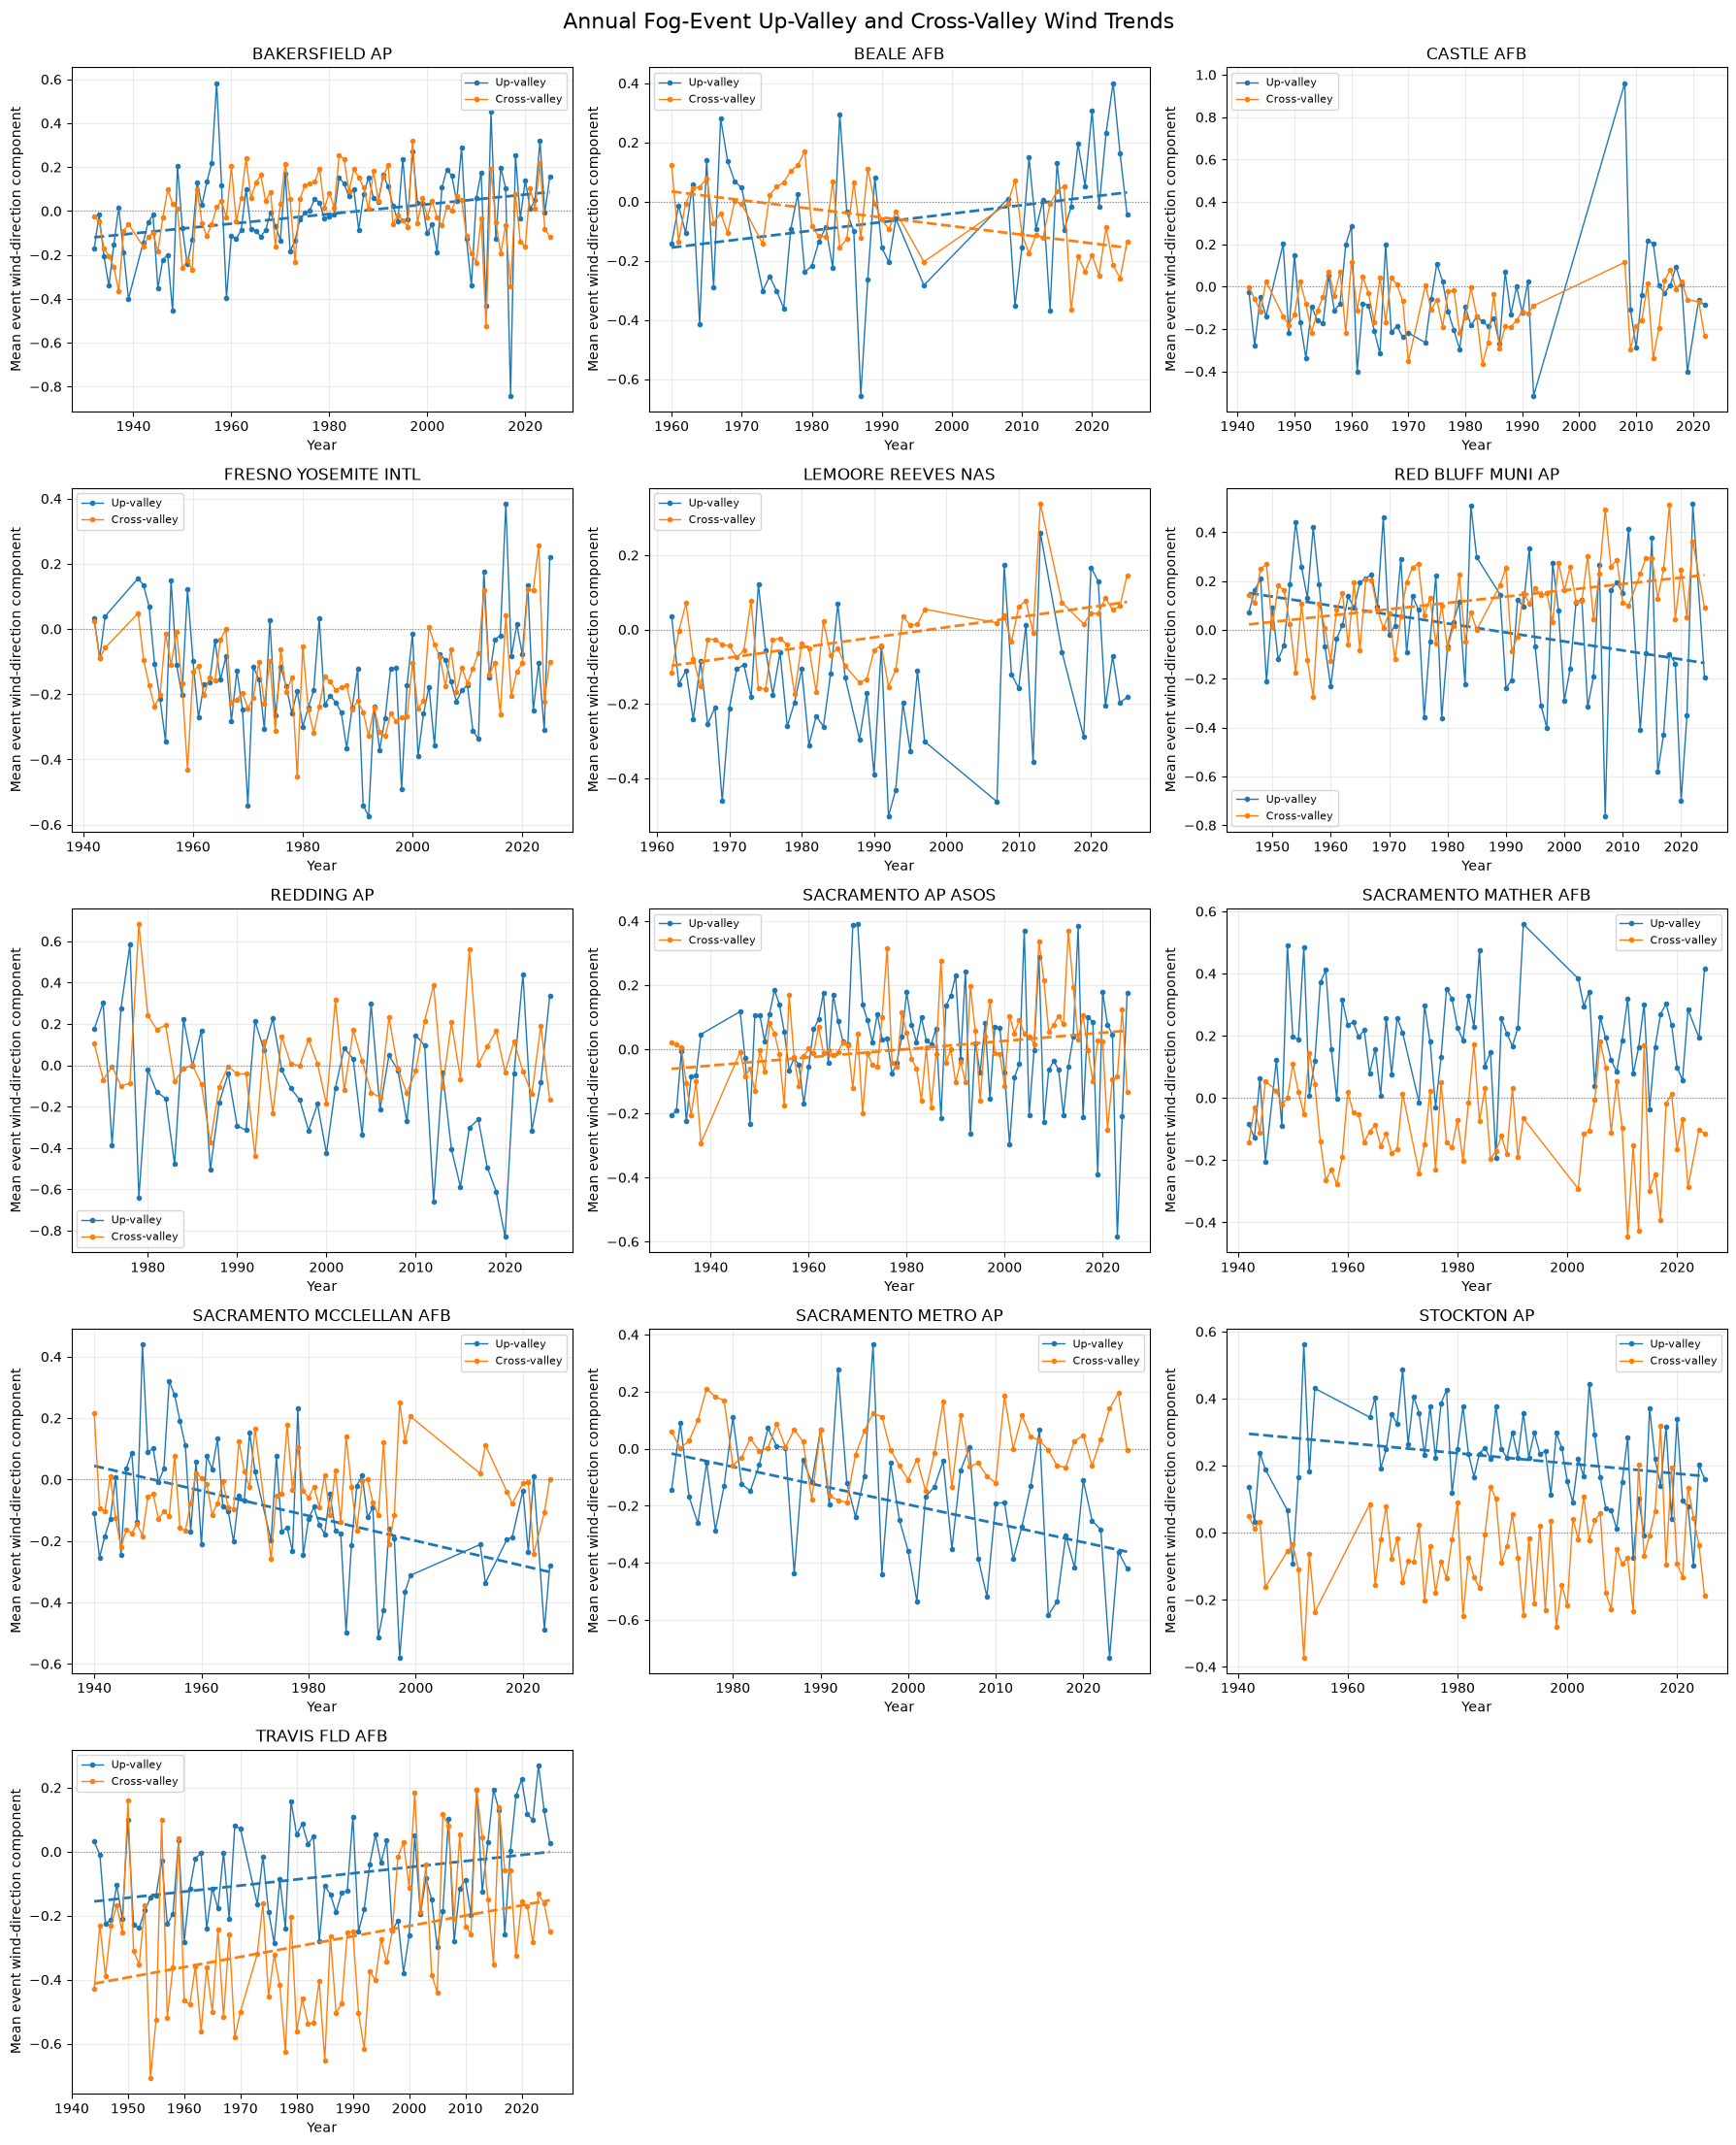

In [22]:
# Annual fog-event wind-direction trends by station.
# Regression lines are shown only when p < 0.05.

# Use the event observations created in cell 23
event_obs = fog_rows[
    [
        "STATION", "event_number", "year", "HourlyWindDirection",
        "up_valley_direction", "cross_valley_direction"
    ]
].copy()

event_obs["HourlyWindDirection"] = pd.to_numeric(
    event_obs["HourlyWindDirection"], errors="coerce"
)
event_obs = event_obs.dropna(subset=["HourlyWindDirection", "year"])

# Calculate circular mean wind direction for each fog event
event_obs["wind_rad"] = np.deg2rad(event_obs["HourlyWindDirection"])
event_obs["u"] = np.cos(event_obs["wind_rad"])
event_obs["v"] = np.sin(event_obs["wind_rad"])

event_wind = (
    event_obs
    .groupby(["STATION", "event_number"], as_index=False)
    .agg(
        year=("year", "first"),
        mean_u=("u", "mean"),
        mean_v=("v", "mean"),
        up_valley_direction=("up_valley_direction", "first"),
        cross_valley_direction=("cross_valley_direction", "first"),
        n_observations=("HourlyWindDirection", "size"),
    )
)

event_wind["event_mean_direction"] = np.mod(
    np.rad2deg(np.arctan2(event_wind["mean_v"], event_wind["mean_u"])),
    360
)

# Calculate event-level alignment with each local axis
# multiply by the wind speed for each event to get the actual wind component along the up-valley direction
event_wind["up_valley_component"] = np.cos(
    np.deg2rad(
        event_wind["event_mean_direction"]
        - event_wind["up_valley_direction"]
    )
)    
# ) * event_wind["n_observations"]

event_wind["cross_valley_component"] = np.cos(
    np.deg2rad(
        event_wind["event_mean_direction"]
        - event_wind["cross_valley_direction"]
    )
) 
# ) * event_wind["n_observations"]

# Annual averages of fog-event directional components
annual_event_wind = (
    event_wind
    .groupby(["STATION", "year"], as_index=False)
    .agg(
        mean_up_valley_component=("up_valley_component", "mean"),
        mean_cross_valley_component=("cross_valley_component", "mean"),
        n_events=("event_number", "size"),
    )
    .sort_values(["STATION", "year"])
)

# Fit trends for each station and component
event_trend_rows = []

for station, group in annual_event_wind.groupby("STATION"):
    for component, column in [
        ("up_valley", "mean_up_valley_component"),
        ("cross_valley", "mean_cross_valley_component"),
    ]:
        data = group[["year", column]].dropna()

        if data["year"].nunique() < 3 or data[column].nunique() < 2:
            continue

        fit = stats.linregress(data["year"], data[column])

        event_trend_rows.append({
            "STATION": station,
            "component": component,
            "start_year": int(data["year"].min()),
            "end_year": int(data["year"].max()),
            "n_years": int(data["year"].nunique()),
            "slope_per_year": fit.slope,
            "slope_per_decade": fit.slope * 10,
            "r_squared": fit.rvalue ** 2,
            "p_value": fit.pvalue,
        })

event_trends = pd.DataFrame(event_trend_rows)
event_trends["significant"] = event_trends["p_value"] < 0.05

display(event_trends.sort_values(["component", "p_value"]))

# Plot both components for every station
stations = sorted(annual_event_wind["STATION"].unique())
ncols = 3
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4.5 * nrows),
    squeeze=False
)
axes = axes.ravel()

for ax, station in zip(axes, stations):
    data = annual_event_wind[
        annual_event_wind["STATION"] == station
    ].sort_values("year")

    for component, column, color, label in [
        (
            "up_valley",
            "mean_up_valley_component",
            "tab:blue",
            "Up-valley",
        ),
        (
            "cross_valley",
            "mean_cross_valley_component",
            "tab:orange",
            "Cross-valley",
        ),
    ]:
        ax.plot(
            data["year"],
            data[column],
            marker="o",
            markersize=3,
            linewidth=1,
            color=color,
            label=label,
        )

        result = event_trends[
            (event_trends["STATION"] == station)
            & (event_trends["component"] == component)
        ]

        # Add a regression line only for significant trends
        if not result.empty and result.iloc[0]["significant"]:
            result = result.iloc[0]
            fitted = (
                result["slope_per_year"] * data["year"]
                + (
                    data[column].mean()
                    - result["slope_per_year"] * data["year"].mean()
                )
            )

            ax.plot(
                data["year"],
                fitted,
                color=color,
                linestyle="--",
                linewidth=2,
            )

    ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
    ax.set_title(station)
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean event wind-direction component")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes[len(stations):]:
    ax.remove()

fig.suptitle(
    "Annual Fog-Event Up-Valley and Cross-Valley Wind Trends\n",
    fontsize=16,
)
plt.tight_layout()
plt.show()

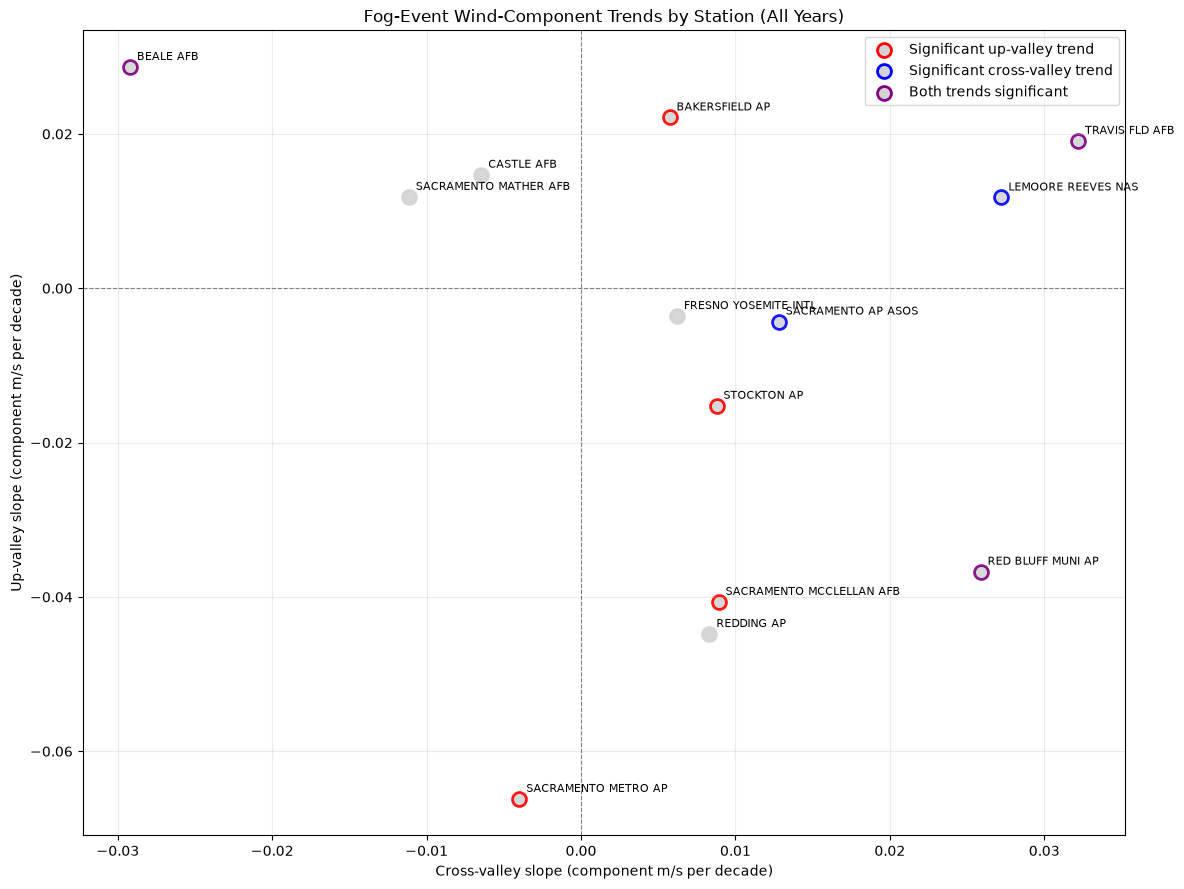

In [23]:
# Plot fog-event trend slopes:
# x-axis = cross-valley slope; y-axis = up-valley slope.
# Red outline = significant up-valley trend
# Blue outline = significant cross-valley trend
# Purple outline = both trends significant

fog_slope_data = (
    event_trends
    .pivot(index="STATION", columns="component",
           values=["slope_per_decade", "p_value"])
    .dropna()
)

fog_slope_data.columns = [
    f"{metric}_{component}"
    for metric, component in fog_slope_data.columns
]

fig, ax = plt.subplots(figsize=(12, 9))

for station, row in fog_slope_data.iterrows():
    significant_up = row["p_value_up_valley"] < 0.05
    significant_cross = row["p_value_cross_valley"] < 0.05

    if significant_up and significant_cross:
        outline_color = "purple"
    elif significant_up:
        outline_color = "red"
    elif significant_cross:
        outline_color = "blue"
    else:
        outline_color = "lightgray"

    point_color = "lightgray"

    ax.scatter(
        row["slope_per_decade_cross_valley"],
        row["slope_per_decade_up_valley"],
        s=100,
        color=point_color,
        edgecolor=outline_color,
        linewidth=2,
        alpha=0.9,
    )

    ax.annotate(
        station,
        (
            row["slope_per_decade_cross_valley"],
            row["slope_per_decade_up_valley"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

for color, label in [
    ("red", "Significant up-valley trend"),
    ("blue", "Significant cross-valley trend"),
    ("purple", "Both trends significant"),
]:
    ax.scatter(
        [], [], s=100, facecolor="lightgray",
        edgecolor=color, linewidth=2, label=label
    )

ax.set_xlabel("Cross-valley slope (component m/s per decade)")
ax.set_ylabel("Up-valley slope (component m/s per decade)")
ax.set_title("Fog-Event Wind-Component Trends by Station (All Years)")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

,STATION,component,start_year,end_year,n_years,slope_per_year,slope_per_decade,r_squared,p_value,significant
9,LEMOORE REEVES NAS,cross_valley,1980,2025,32,0.004342,0.043416,0.434998,0.000040,True
25,TRAVIS FLD AFB,cross_valley,1980,2025,46,0.009199,0.091989,0.316332,0.000047,True
7,FRESNO YOSEMITE INTL,cross_valley,1980,2025,46,0.005259,0.052587,0.294556,0.000098,True
1,BAKERSFIELD AP,cross_valley,1980,2025,46,-0.005623,-0.056227,0.221645,0.000960,True
11,RED BLUFF MUNI AP,cross_valley,1980,2024,40,0.005014,0.050143,0.215749,0.002533,True
3,BEALE AFB,cross_valley,1980,2025,32,-0.002748,-0.027479,0.149495,0.028816,True
5,CASTLE AFB,cross_valley,1980,2022,27,0.002494,0.024943,0.088591,0.131599,False
21,SACRAMENTO METRO AP,cross_valley,1980,2025,46,0.001486,0.014864,0.041292,0.175594,False
17,SACRAMENTO MATHER AFB,cross_valley,1980,2025,36,-0.002116,-0.021164,0.038568,0.250987,False
23,STOCKTON AP,cross_valley,1980,2025,46,0.001731,0.017315,0.028958,0.258195,False


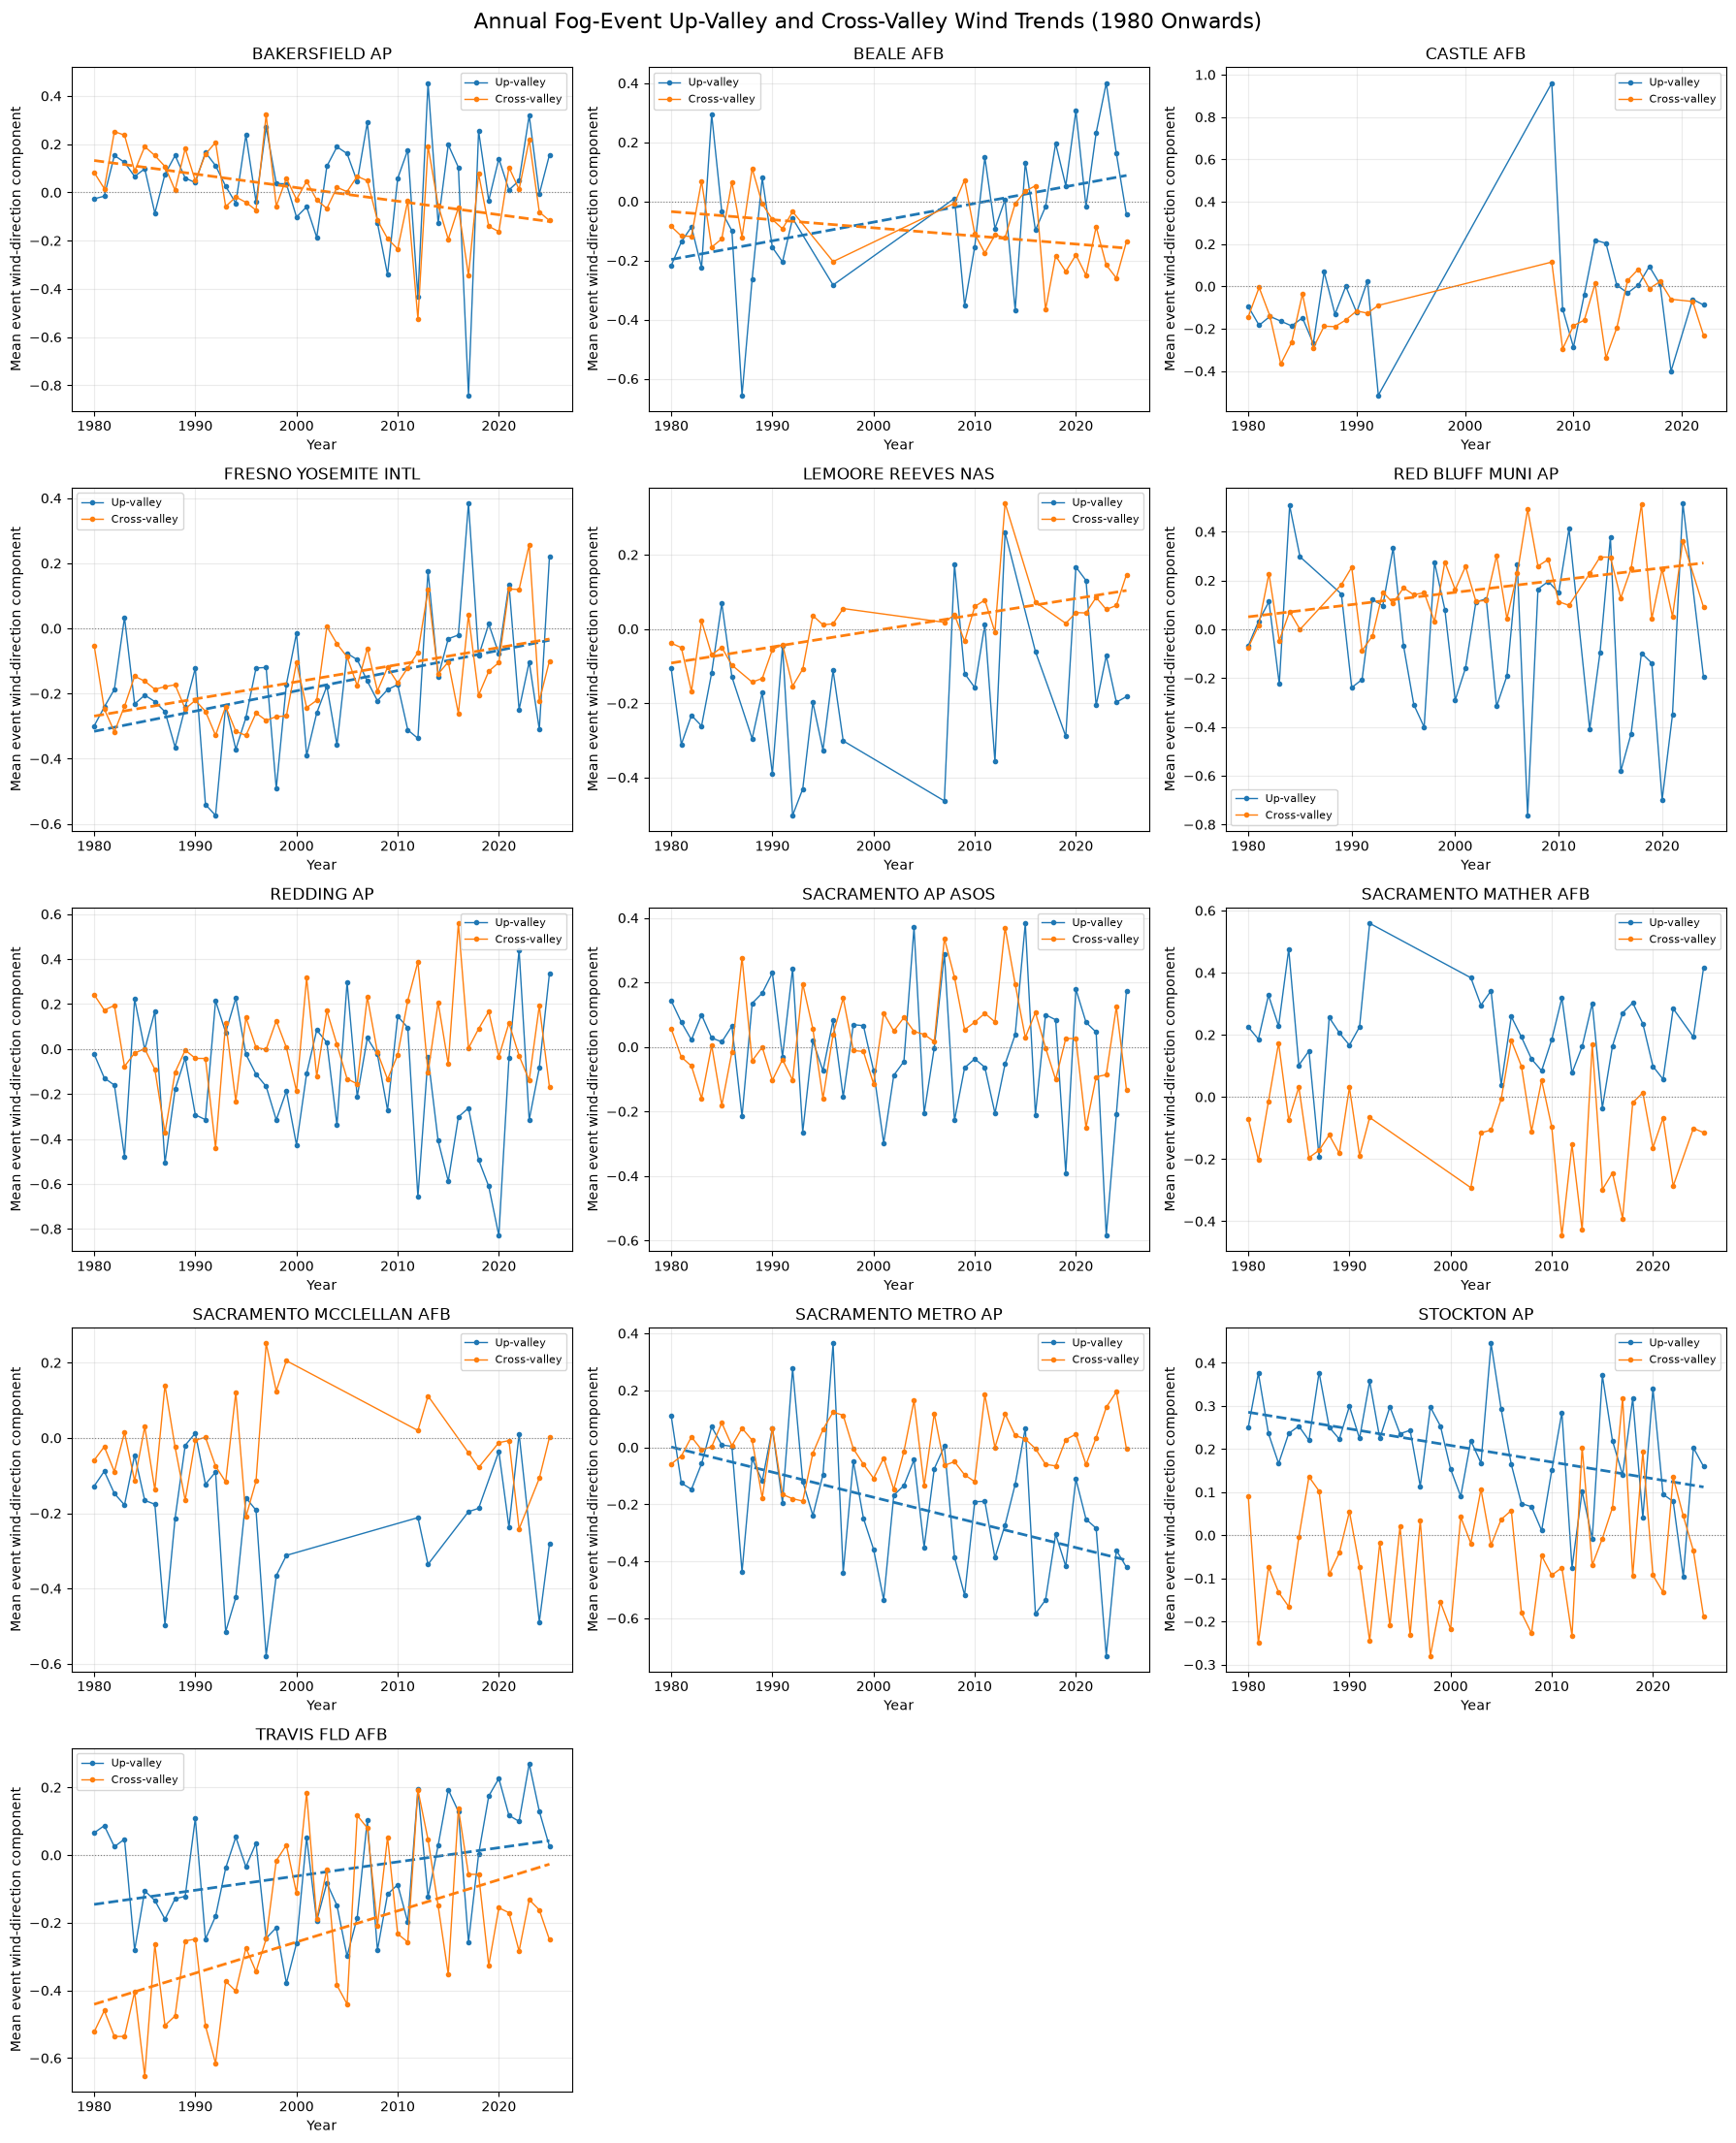

In [24]:
# Annual fog-event wind-direction trends by station.
# Only for years since 1980
# Regression lines are shown only when p < 0.05.

# Use the event observations created in cell 23
event_obs1980 = fog_rows[
    [
        "STATION", "event_number", "year", "HourlyWindDirection",
        "up_valley_direction", "cross_valley_direction"
    ]
].copy()

event_obs1980["HourlyWindDirection"] = pd.to_numeric(
    event_obs1980["HourlyWindDirection"], errors="coerce"
)
event_obs1980 = event_obs1980.dropna(subset=["HourlyWindDirection", "year"])
event_obs1980 = event_obs1980[event_obs1980["year"] >= 1980]

# Calculate circular mean wind direction for each fog event
event_obs1980["wind_rad"] = np.deg2rad(event_obs1980["HourlyWindDirection"])
event_obs1980["u"] = np.cos(event_obs1980["wind_rad"])
event_obs1980["v"] = np.sin(event_obs1980["wind_rad"])

event_wind1980 = (
    event_obs1980
    .groupby(["STATION", "event_number"], as_index=False)
    .agg(
        year=("year", "first"),
        mean_u=("u", "mean"),
        mean_v=("v", "mean"),
        up_valley_direction=("up_valley_direction", "first"),
        cross_valley_direction=("cross_valley_direction", "first"),
        n_observations=("HourlyWindDirection", "size"),
    )
)

event_wind1980["event_mean_direction"] = np.mod(
    np.rad2deg(np.arctan2(event_wind1980["mean_v"], event_wind1980["mean_u"])),
    360
)

# Calculate event-level alignment with each local axis
# multiply by the wind magnitude to get the actual wind component along the up-valley direction
# Here we only consider the angular alignment, not the wind magnitude
event_wind1980["up_valley_component"] = np.cos(
    np.deg2rad(
        event_wind1980["event_mean_direction"]
        - event_wind1980["up_valley_direction"]
    )
)
# ) * event_wind1980["n_observations"]

event_wind1980["cross_valley_component"] = np.cos(
    np.deg2rad(
        event_wind1980["event_mean_direction"]
        - event_wind1980["cross_valley_direction"]
    )
)
# ) * event_wind1980["n_observations"]

# Annual averages of fog-event directional components
annual_event_wind1980 = (
    event_wind1980
    .groupby(["STATION", "year"], as_index=False)
    .agg(
        mean_up_valley_component=("up_valley_component", "mean"),
        mean_cross_valley_component=("cross_valley_component", "mean"),
        n_events=("event_number", "size"),
    )
    .sort_values(["STATION", "year"])
)

# Fit trends for each station and component
event_trend_rows = []

for station, group in annual_event_wind1980.groupby("STATION"):
    for component, column in [
        ("up_valley", "mean_up_valley_component"),
        ("cross_valley", "mean_cross_valley_component"),
    ]:
        data = group[["year", column]].dropna()

        if data["year"].nunique() < 3 or data[column].nunique() < 2:
            continue

        fit = stats.linregress(data["year"], data[column])

        event_trend_rows.append({
            "STATION": station,
            "component": component,
            "start_year": int(data["year"].min()),
            "end_year": int(data["year"].max()),
            "n_years": int(data["year"].nunique()),
            "slope_per_year": fit.slope,
            "slope_per_decade": fit.slope * 10,
            "r_squared": fit.rvalue ** 2,
            "p_value": fit.pvalue,
        })

event_trends1980 = pd.DataFrame(event_trend_rows)
event_trends1980["significant"] = event_trends1980["p_value"] < 0.05

display(event_trends1980.sort_values(["component", "p_value"]))

# Plot both components for every station
stations = sorted(annual_event_wind1980["STATION"].unique())
ncols = 3
nrows = int(np.ceil(len(stations) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4.5 * nrows),
    squeeze=False
)
axes = axes.ravel()

for ax, station in zip(axes, stations):
    data = annual_event_wind1980[
        annual_event_wind1980["STATION"] == station
    ].sort_values("year")

    for component, column, color, label in [
        (
            "up_valley",
            "mean_up_valley_component",
            "tab:blue",
            "Up-valley",
        ),
        (
            "cross_valley",
            "mean_cross_valley_component",
            "tab:orange",
            "Cross-valley",
        ),
    ]:
        ax.plot(
            data["year"],
            data[column],
            marker="o",
            markersize=3,
            linewidth=1,
            color=color,
            label=label,
        )

        result = event_trends1980[
            (event_trends1980["STATION"] == station)
            & (event_trends1980["component"] == component)
        ]

        # Add a regression line only for significant trends
        if not result.empty and result.iloc[0]["significant"]:
            result = result.iloc[0]
            fitted = (
                result["slope_per_year"] * data["year"]
                + (
                    data[column].mean()
                    - result["slope_per_year"] * data["year"].mean()
                )
            )

            ax.plot(
                data["year"],
                fitted,
                color=color,
                linestyle="--",
                linewidth=2,
            )

    ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
    ax.set_title(station)
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean event wind-direction component")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes[len(stations):]:
    ax.remove()

fig.suptitle(
    "Annual Fog-Event Up-Valley and Cross-Valley Wind Trends (1980 Onwards)\n",
    fontsize=16,
)
plt.tight_layout()
plt.show()

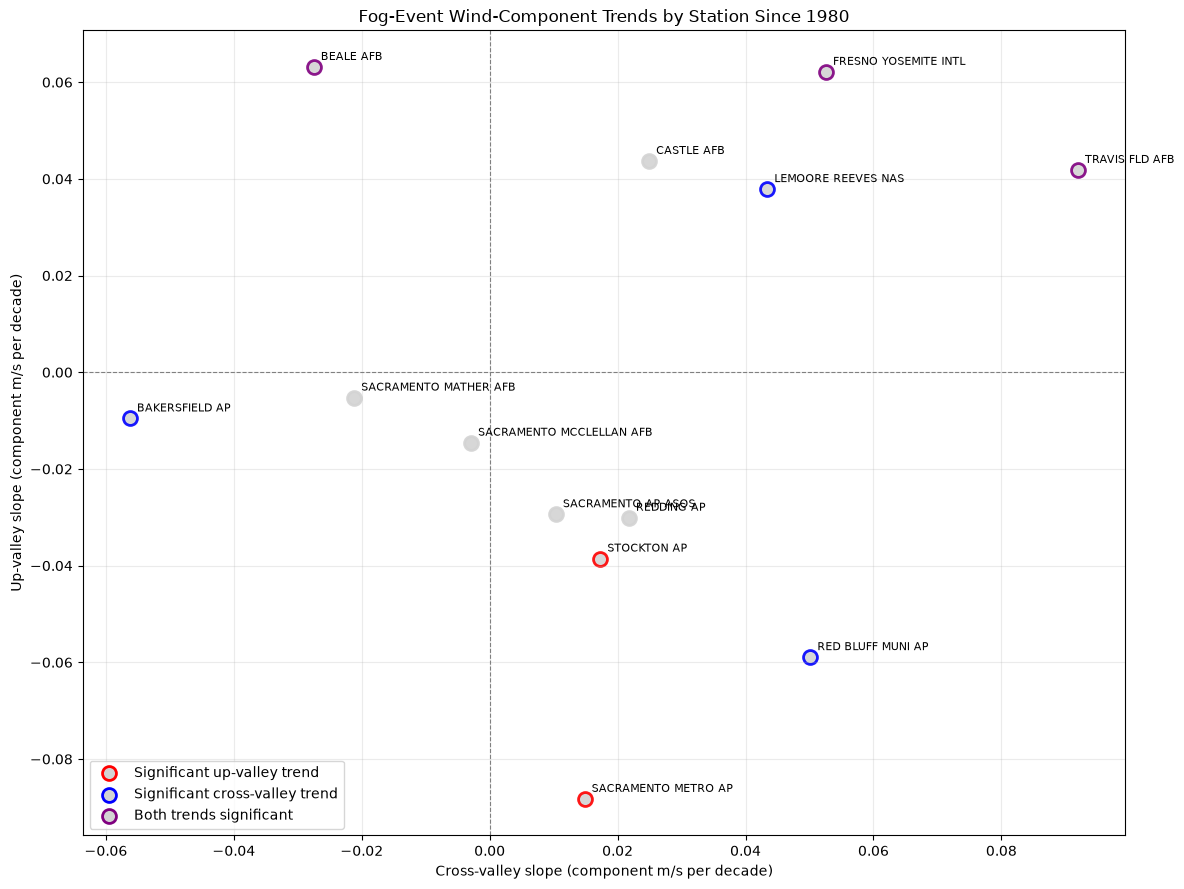

In [25]:
# Plot fog-event trend slopes since 1980
# x-axis = cross-valley slope; y-axis = up-valley slope.
# Red outline = significant up-valley trend
# Blue outline = significant cross-valley trend
# Purple outline = both trends significant

fog_slope_data1980 = (
    event_trends1980
    .pivot(index="STATION", columns="component",
           values=["slope_per_decade", "p_value"])
    .dropna()
)

fog_slope_data1980.columns = [
    f"{metric}_{component}"
    for metric, component in fog_slope_data1980.columns
]

fig, ax = plt.subplots(figsize=(12, 9))

for station, row in fog_slope_data1980.iterrows():
    significant_up1980 = row["p_value_up_valley"] < 0.05
    significant_cross1980 = row["p_value_cross_valley"] < 0.05

    if significant_up1980 and significant_cross1980:
        outline_color = "purple"
    elif significant_up1980:
        outline_color = "red"
    elif significant_cross1980:
        outline_color = "blue"
    else:
        outline_color = "lightgray"

    ax.scatter(
        row["slope_per_decade_cross_valley"],
        row["slope_per_decade_up_valley"],
        s=100,
        facecolor="lightgray",
        edgecolor=outline_color,
        linewidth=2,
        alpha=0.9,
    )

    ax.annotate(
        station,
        (
            row["slope_per_decade_cross_valley"],
            row["slope_per_decade_up_valley"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

for color, label in [
    ("red", "Significant up-valley trend"),
    ("blue", "Significant cross-valley trend"),
    ("purple", "Both trends significant"),
]:
    ax.scatter(
        [], [], s=100, facecolor="lightgray",
        edgecolor=color, linewidth=2, label=label
    )

ax.set_xlabel("Cross-valley slope (component m/s per decade)")
ax.set_ylabel("Up-valley slope (component m/s per decade)")
ax.set_title("Fog-Event Wind-Component Trends by Station Since 1980")
ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

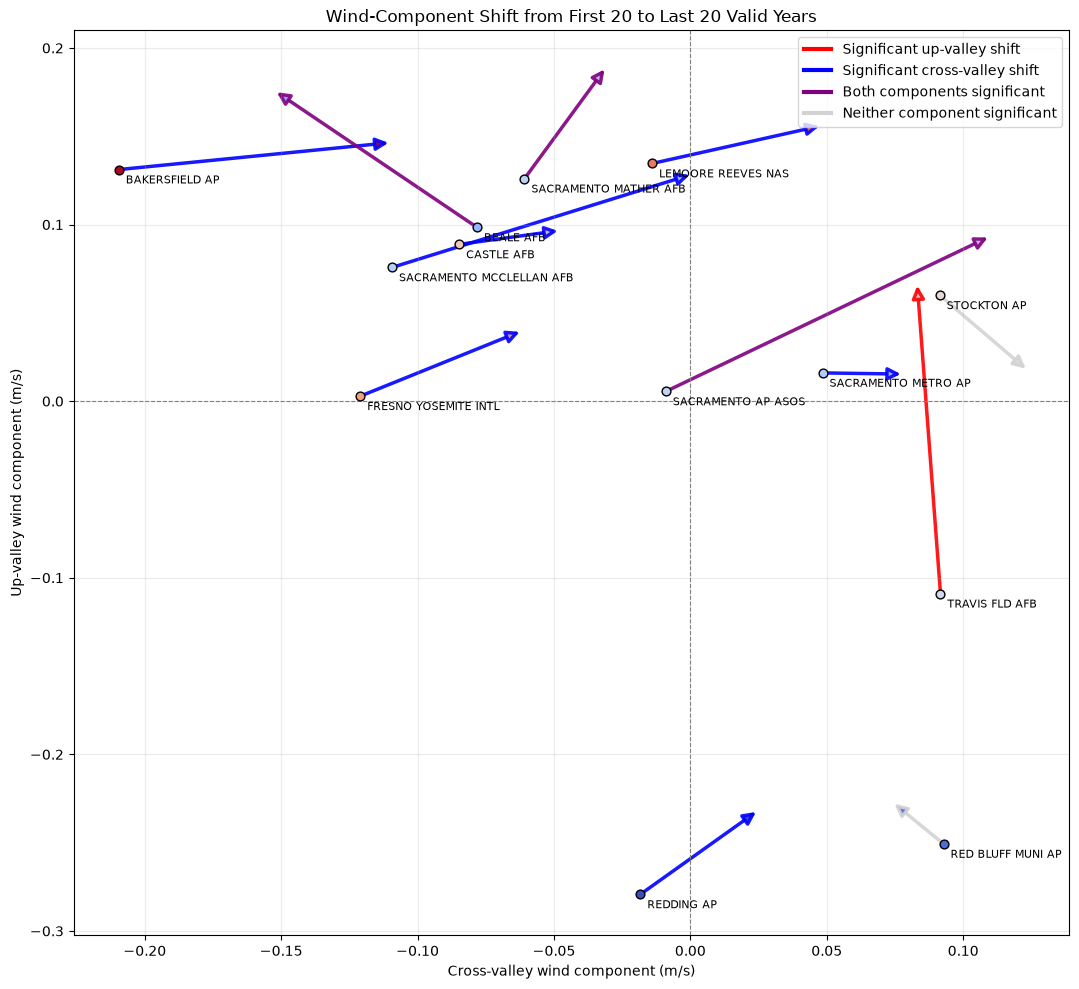

In [26]:
# First and last 20 valid annual observations for each station
# make it so the labels for station arrows do not overlap with the arrows themselves
# Comment every line to explain what it does
# Create a figure and axis for the plot
fig, ax = plt.subplots(figsize=(11, 10))
# Initialize an empty list to store arrow data for each station
arrow_rows = []

# Loop through each station and process its data
for station, group in annual_avg_wind.groupby("STATION"):
    # Drop rows with missing values for the required columns and sort by year
    group = (
        group.dropna(
            subset=[
                "mean_up_valley_component",
                "mean_cross_valley_component",
                "latitude",
            ]
        )
        .sort_values("year")
    )

    # Skip stations with less than 2 valid observations
    if len(group) < 2:
        continue

    # Determine the number of years to consider for the first and last periods (up to 20)
    n_periods = min(20, len(group))
    # Select the first and last periods
    first_period = group.iloc[:n_periods]
    last_period = group.iloc[-n_periods:]

    # Get the trend information for the current station
    station_trends = trend_df[trend_df["STATION"] == station]
    # Determine if the up-valley and cross-valley components have significant trends
    # A trend is considered significant if the p-value is less than 0.05    
    # Check for significant up-valley trend

    sig_up = (
        not station_trends[
            station_trends["component"] == "up_valley"
        ].empty
        and station_trends[
            station_trends["component"] == "up_valley"
        ].iloc[0]["p_value"] < 0.05
    )

    sig_cross = (
        not station_trends[
            station_trends["component"] == "cross_valley"
        ].empty
        and station_trends[
            station_trends["component"] == "cross_valley"
        ].iloc[0]["p_value"] < 0.05
    )

    # Determine the outline color based on significance of trends
    if sig_up and sig_cross:
        outline_color = "purple"
    elif sig_up:
        outline_color = "red"
    elif sig_cross:
        outline_color = "blue"
    else:
        outline_color = "lightgray"

    arrow_rows.append({
        "STATION": station,
        "start_x": first_period["mean_cross_valley_component"].mean(),
        "start_y": first_period["mean_up_valley_component"].mean(),
        "end_x": last_period["mean_cross_valley_component"].mean(),
        "end_y": last_period["mean_up_valley_component"].mean(),
        "latitude": group["latitude"].iloc[0],
        "outline_color": outline_color,
    })

arrow_df = pd.DataFrame(arrow_rows)

lat_min = arrow_df["latitude"].min()
lat_range = arrow_df["latitude"].max() - lat_min
lat_range = lat_range if lat_range != 0 else 1

for _, row in arrow_df.iterrows():
    fill_color = plt.cm.coolwarm_r(
        (row["latitude"] - lat_min) / lat_range
    )

    ax.add_patch(
        FancyArrowPatch(
            (row["start_x"], row["start_y"]),
            (row["end_x"], row["end_y"]),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2.5,
            edgecolor=row["outline_color"],
            facecolor=fill_color,
            alpha=0.9,
        )
    )

    ax.scatter(
        row["start_x"],
        row["start_y"],
        color=fill_color,
        edgecolor="black",
        s=40,
        zorder=3,
    )

    ax.annotate(
        row["STATION"],
        (row["start_x"], row["start_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

# Legend for significance outlines
# Each color represents the significance of the trends for the up-valley and cross-valley components    
# Red indicates a significant up-valley shift, blue indicates a significant cross-valley shift,
# purple indicates both components are significant, and lightgray indicates neither component is significant
for color, label in [
    ("red", "Significant up-valley shift"),
    ("blue", "Significant cross-valley shift"),
    ("purple", "Both components significant"),
    ("lightgray", "Neither component significant"),
]:
    ax.plot([], [], color=color, linewidth=3, label=label)

# Draw the reference lines at zero for both axes
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("Cross-valley wind component (m/s)")
ax.set_ylabel("Up-valley wind component (m/s)")
ax.set_title(
    "Wind-Component Shift from First 20 to Last 20 Valid Years"
)
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

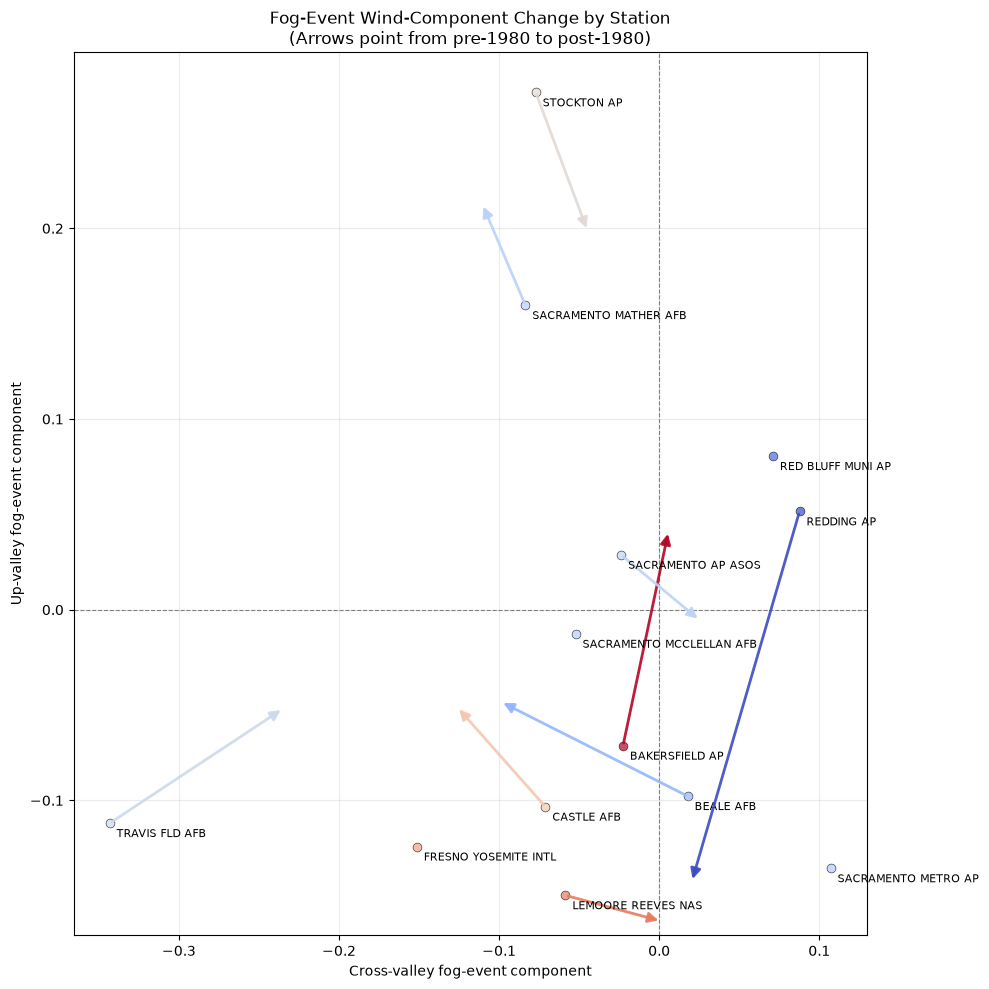

In [27]:
# Fog-event wind-component shifts:
# pre-1980 years compared with post-1980 years (1980 onward)

fog_annual = annual_event_wind.merge(
    station_lat,
    on="STATION",
    how="left"
)

fig, ax = plt.subplots(figsize=(10, 10))
arrow_rows = []

for station, group in fog_annual.groupby("STATION"):
    group = group.dropna(
        subset=[
            "mean_up_valley_component",
            "mean_cross_valley_component",
            "latitude",
        ]
    ).sort_values("year")

    pre_1980 = group[group["year"] < 1980]
    post_1980 = group[group["year"] >= 1980]

    if pre_1980.empty or post_1980.empty:
        continue

    arrow_rows.append({
        "STATION": station,
        "start_x": pre_1980["mean_cross_valley_component"].mean(),
        "start_y": pre_1980["mean_up_valley_component"].mean(),
        "end_x": post_1980["mean_cross_valley_component"].mean(),
        "end_y": post_1980["mean_up_valley_component"].mean(),
        "latitude": group["latitude"].iloc[0],
    })

arrow_df = pd.DataFrame(arrow_rows)

if arrow_df.empty:
    raise ValueError("No stations contain both pre-1980 and post-1980 fog-event data.")

lat_min = arrow_df["latitude"].min()
lat_range = arrow_df["latitude"].max() - lat_min
lat_range = lat_range if lat_range != 0 else 1

for _, row in arrow_df.iterrows():
    color = plt.cm.coolwarm_r(
        (row["latitude"] - lat_min) / lat_range
    )

    ax.annotate(
        "",
        xy=(row["end_x"], row["end_y"]),
        xytext=(row["start_x"], row["start_y"]),
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            linewidth=2,
            mutation_scale=15,
            alpha=0.9,
        ),
    )

    ax.scatter(
        row["start_x"],
        row["start_y"],
        color=color,
        marker="o",
        s=40,
        edgecolors="black",
        linewidths=0.5,
        alpha=0.7,
    )

    ax.annotate(
        row["STATION"],
        (row["start_x"], row["start_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("Cross-valley fog-event component")
ax.set_ylabel("Up-valley fog-event component")
ax.set_title(
    "Fog-Event Wind-Component Change by Station\n"
    "(Arrows point from pre-1980 to post-1980)"
)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

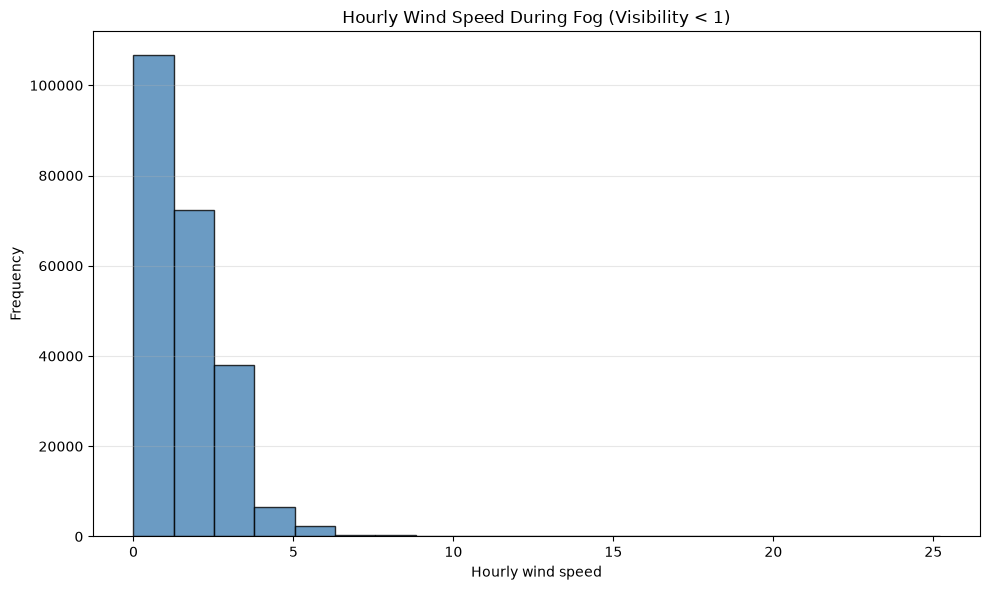

In [28]:
fog_wind_speed = pd.to_numeric(
    CV_filtered_rows.loc[
        (CV_filtered_rows["HourlyVisibility"] < 1)
        #precipitation in mm
        & (CV_filtered_rows["HourlyPrecipitation"] < 0.03),
        "HourlyWindSpeed"
    ],
    errors="coerce"
).dropna()

plt.figure(figsize=(10, 6))
plt.hist(
    fog_wind_speed,
    bins=20,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Hourly wind speed")
plt.ylabel("Frequency")
plt.title("Hourly Wind Speed During Fog (Visibility < 1)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

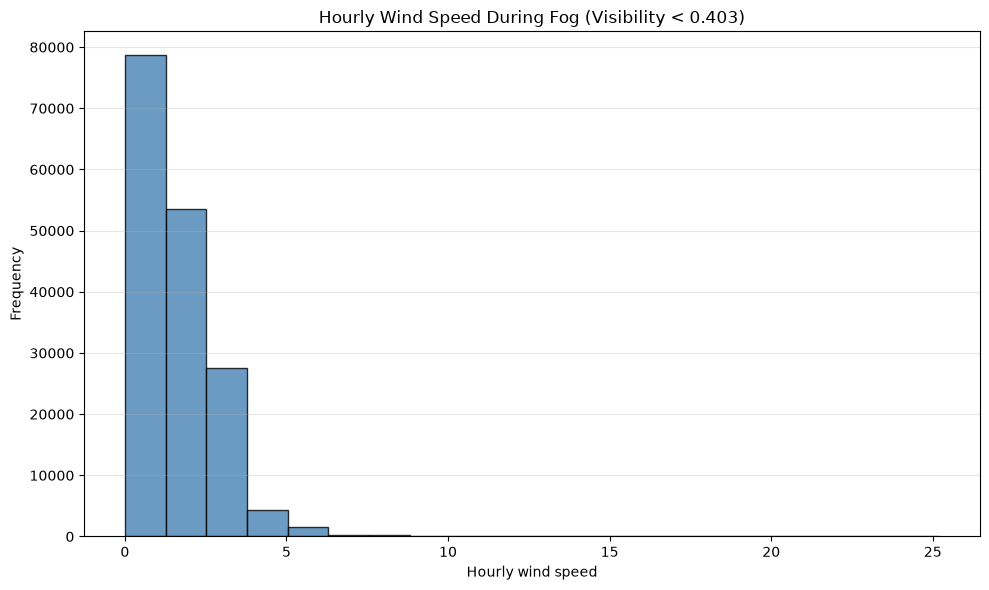

In [29]:
fog_wind_speed = pd.to_numeric(
    CV_filtered_rows.loc[
        (CV_filtered_rows["HourlyVisibility"] < 0.403)
        & (CV_filtered_rows["HourlyPrecipitation"] < 0.03),
        "HourlyWindSpeed"
    ],
    errors="coerce"
).dropna()

plt.figure(figsize=(10, 6))
plt.hist(
    fog_wind_speed,
    bins=20,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Hourly wind speed")
plt.ylabel("Frequency")
plt.title("Hourly Wind Speed During Fog (Visibility < 0.403)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

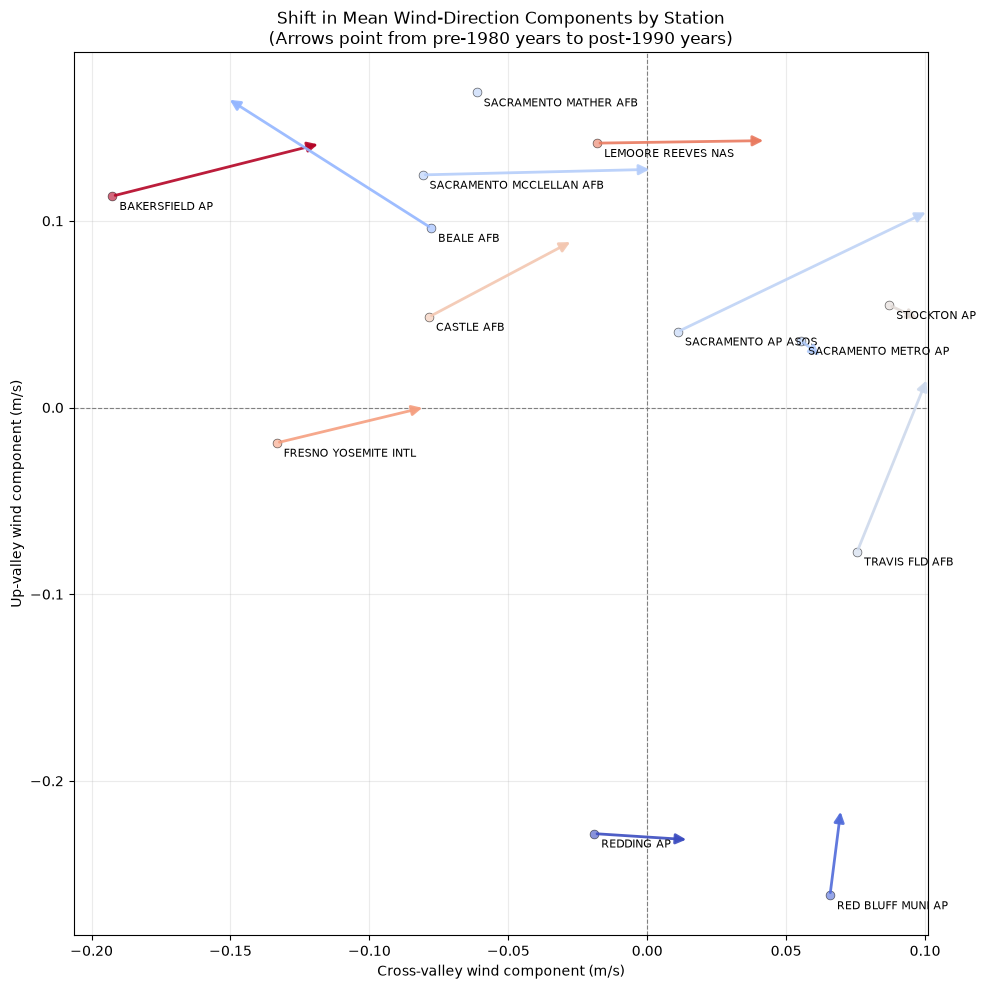

In [30]:
# Wind direction shift plot: arrows from mean (up-valley, cross-valley) components
# use pre-1980 years compared to post-1990 years

fig, ax = plt.subplots(figsize=(10, 10))

arrow_rows = []

for station, g in annual_avg_wind.groupby("STATION"):
    g = g.dropna(subset=["mean_up_valley_component", "mean_cross_valley_component"])
    g = g.sort_values("year")

    years = g["year"].unique()
    if len(years) < 2:
        continue

    first_period = g[g["year"] < 1980]
    last_period = g[g["year"] > 1990]

    if first_period.empty or last_period.empty:
        continue

    start_x = first_period["mean_cross_valley_component"].mean()
    start_y = first_period["mean_up_valley_component"].mean()
    end_x = last_period["mean_cross_valley_component"].mean()
    end_y = last_period["mean_up_valley_component"].mean()

    lat = g["latitude"].iloc[0] if "latitude" in g.columns else np.nan

    arrow_rows.append({
        "STATION": station,
        "start_x": start_x,
        "start_y": start_y,
        "end_x": end_x,
        "end_y": end_y,
        "latitude": lat,
        "first_years_range": (int(first_period["year"].min()), int(first_period["year"].max())),
        "last_years_range": (int(last_period["year"].min()), int(last_period["year"].max())),
    })

arrow_df = pd.DataFrame(arrow_rows)

lat_min_local = arrow_df["latitude"].min()
lat_max_local = arrow_df["latitude"].max()
lat_range_local = lat_max_local - lat_min_local if lat_max_local != lat_min_local else 1

for _, row in arrow_df.iterrows():
    color = plt.cm.coolwarm_r((row["latitude"] - lat_min_local) / lat_range_local)

    ax.annotate(
        "",
        xy=(row["end_x"], row["end_y"]),
        xytext=(row["start_x"], row["start_y"]),
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            linewidth=2,
            alpha=0.9,
            mutation_scale=15,
        ),
    )

    # Mark the starting point
    ax.scatter(
        row["start_x"], row["start_y"],
        color=color, marker="o", s=40, alpha=0.6, edgecolors="black", linewidths=0.5
    )

    ax.annotate(
        row["STATION"],
        (row["start_x"], row["start_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("Cross-valley wind component (m/s)")
ax.set_ylabel("Up-valley wind component (m/s)")
ax.set_title(
    "Shift in Mean Wind-Direction Components by Station\n"
    "(Arrows point from pre-1980 years to post-1990 years)"
)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

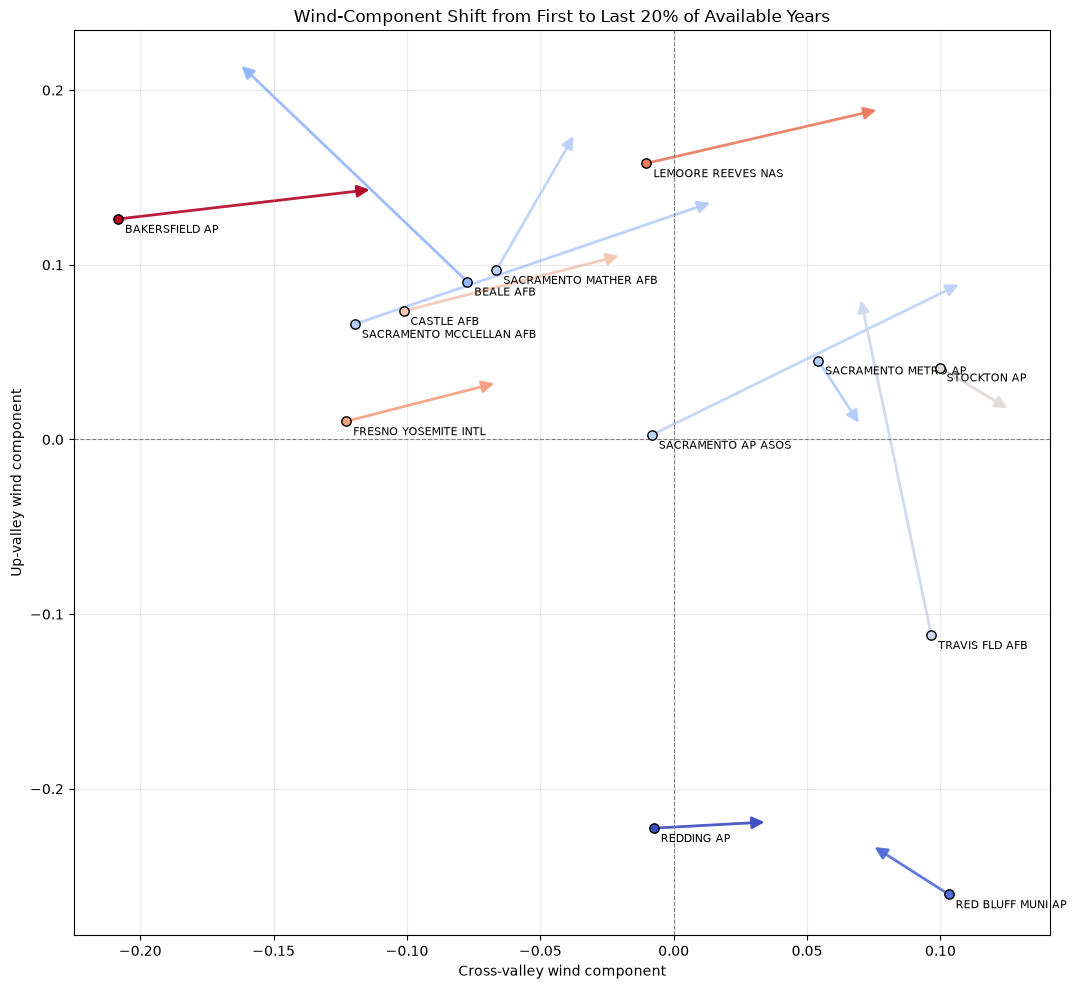

,STATION,start_x,start_y,end_x,end_y,latitude,first_years,last_years
0,BAKERSFIELD AP,-0.208319,0.126216,-0.112941,0.143177,35.4342,1932–1952,2007–2025
1,BEALE AFB,-0.077388,0.090341,-0.162813,0.215061,39.1333,1960–1969,2016–2025
2,CASTLE AFB,-0.101261,0.073514,-0.019509,0.105471,37.3833,1942–1956,2009–2022
3,FRESNO YOSEMITE INTL,-0.122755,0.010400,-0.066238,0.032469,36.7800,1942–1962,2010–2025
4,LEMOORE REEVES NAS,-0.010201,0.158107,0.077027,0.188891,36.3333,1962–1971,2012–2025
5,RED BLUFF MUNI AP,0.103079,-0.260431,0.074400,-0.232474,40.1519,1946–1960,2009–2024
6,REDDING AP,-0.007467,-0.222530,0.035119,-0.218978,40.5147,1974–1984,2015–2025
7,SACRAMENTO AP ASOS,-0.008184,0.002593,0.107811,0.089445,38.5067,1932–1956,2008–2025
8,SACRAMENTO MATHER AFB,-0.066447,0.097021,-0.036956,0.175115,38.5667,1942–1957,2010–2025
9,SACRAMENTO MCCLELLAN AFB,-0.119483,0.066090,0.014687,0.136022,38.6667,1940–1953,1995–2025


In [31]:
# Wind-component shift using the first and last 20% of valid annual data
# for each station across all available years.

fig, ax = plt.subplots(figsize=(11, 10))
arrow_rows = []

for station, group in annual_avg_wind.groupby("STATION"):
    group = (
        group[
            [
                "STATION",
                "year",
                "mean_up_valley_component",
                "mean_cross_valley_component",
                "latitude",
            ]
        ]
        .dropna()
        .sort_values("year")
    )

    if group.empty:
        continue

    n_periods = max(1, int(np.ceil(len(group) * 0.20)))

    first_period = group.iloc[:n_periods]
    last_period = group.iloc[-n_periods:]

    arrow_rows.append({
        "STATION": station,
        "start_x": first_period["mean_cross_valley_component"].mean(),
        "start_y": first_period["mean_up_valley_component"].mean(),
        "end_x": last_period["mean_cross_valley_component"].mean(),
        "end_y": last_period["mean_up_valley_component"].mean(),
        "latitude": group["latitude"].iloc[0],
        "first_years": f"{first_period['year'].min()}–{first_period['year'].max()}",
        "last_years": f"{last_period['year'].min()}–{last_period['year'].max()}",
    })

arrow_df_20pct = pd.DataFrame(arrow_rows)

lat_min = arrow_df_20pct["latitude"].min()
lat_range = arrow_df_20pct["latitude"].max() - lat_min
lat_range = lat_range if lat_range != 0 else 1

for _, row in arrow_df_20pct.iterrows():
    color = plt.cm.coolwarm_r(
        (row["latitude"] - lat_min) / lat_range
    )

    ax.add_patch(
        FancyArrowPatch(
            (row["start_x"], row["start_y"]),
            (row["end_x"], row["end_y"]),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2,
            color=color,
            alpha=0.9,
        )
    )

    ax.scatter(
        row["start_x"],
        row["start_y"],
        color=color,
        edgecolor="black",
        s=45,
        zorder=3,
    )

    ax.annotate(
        row["STATION"],
        (row["start_x"], row["start_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("Cross-valley wind component")
ax.set_ylabel("Up-valley wind component")
ax.set_title(
    "Wind-Component Shift from First to Last 20% of Available Years"
)
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

display(arrow_df_20pct)

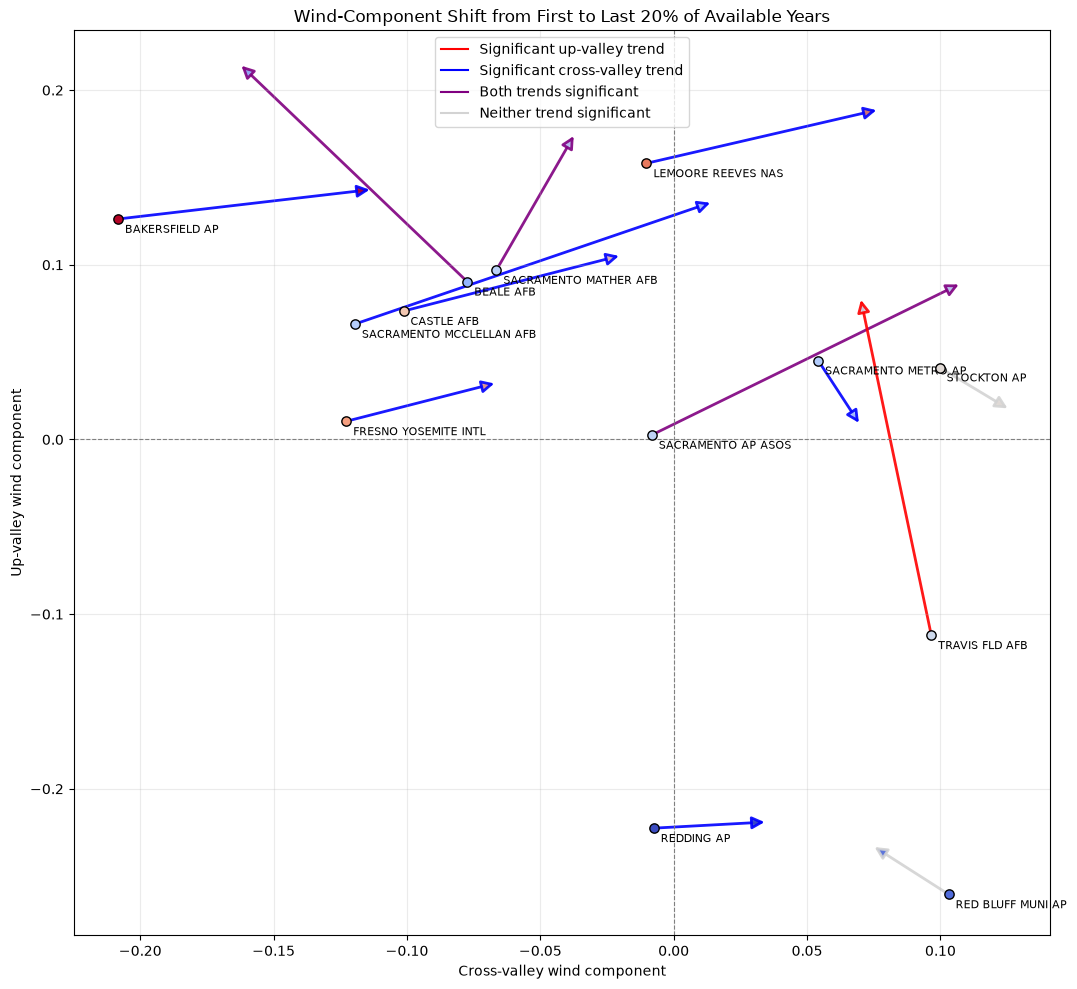

,STATION,start_x,start_y,end_x,end_y,latitude,outline_color
0,BAKERSFIELD AP,-0.208319,0.126216,-0.112941,0.143177,35.4342,blue
1,BEALE AFB,-0.077388,0.090341,-0.162813,0.215061,39.1333,purple
2,CASTLE AFB,-0.101261,0.073514,-0.019509,0.105471,37.3833,blue
3,FRESNO YOSEMITE INTL,-0.122755,0.010400,-0.066238,0.032469,36.7800,blue
4,LEMOORE REEVES NAS,-0.010201,0.158107,0.077027,0.188891,36.3333,blue
5,RED BLUFF MUNI AP,0.103079,-0.260431,0.074400,-0.232474,40.1519,lightgray
6,REDDING AP,-0.007467,-0.222530,0.035119,-0.218978,40.5147,blue
7,SACRAMENTO AP ASOS,-0.008184,0.002593,0.107811,0.089445,38.5067,purple
8,SACRAMENTO MATHER AFB,-0.066447,0.097021,-0.036956,0.175115,38.5667,purple
9,SACRAMENTO MCCLELLAN AFB,-0.119483,0.066090,0.014687,0.136022,38.6667,blue


In [32]:
# Wind-component shifts using the first and last 20% of valid annual data.
# Outline colors indicate significant trends:
# red = significant up-valley trend
# blue = significant cross-valley trend
# purple = both significant

# make the arrows outlined in colors, not the datapoints

fig, ax = plt.subplots(figsize=(11, 10))
arrow_rows_20pct = []

for station, group in annual_avg_wind.groupby("STATION"):
    group = (
        group[
            [
                "STATION",
                "year",
                "mean_up_valley_component",
                "mean_cross_valley_component",
                "latitude",
            ]
        ]
        .dropna()
        .sort_values("year")
    )

    if len(group) < 2:
        continue

    n_periods = max(1, int(np.ceil(len(group) * 0.20)))
    first_period = group.iloc[:n_periods]
    last_period = group.iloc[-n_periods:]

    station_trends = trend_df[trend_df["STATION"] == station]

    up_trend = station_trends[
        station_trends["component"] == "up_valley"
    ]
    cross_trend = station_trends[
        station_trends["component"] == "cross_valley"
    ]

    sig_up = not up_trend.empty and up_trend.iloc[0]["p_value"] < 0.05
    sig_cross = not cross_trend.empty and cross_trend.iloc[0]["p_value"] < 0.05

    if sig_up and sig_cross:
        outline_color = "purple"
    elif sig_up:
        outline_color = "red"
    elif sig_cross:
        outline_color = "blue"
    else:
        outline_color = "lightgray"

    arrow_rows_20pct.append({
        "STATION": station,
        "start_x": first_period["mean_cross_valley_component"].mean(),
        "start_y": first_period["mean_up_valley_component"].mean(),
        "end_x": last_period["mean_cross_valley_component"].mean(),
        "end_y": last_period["mean_up_valley_component"].mean(),
        "latitude": group["latitude"].iloc[0],
        "outline_color": outline_color,
    })

arrow_df_20pct_sig = pd.DataFrame(arrow_rows_20pct)

lat_min = arrow_df_20pct_sig["latitude"].min()
lat_range = (
    arrow_df_20pct_sig["latitude"].max() - lat_min
    if len(arrow_df_20pct_sig) > 1
    else 1
)

for _, row in arrow_df_20pct_sig.iterrows():
    latitude_color = plt.cm.coolwarm_r(
        (row["latitude"] - lat_min) / lat_range
    )

    ax.add_patch(
        FancyArrowPatch(
            (row["start_x"], row["start_y"]),
            (row["end_x"], row["end_y"]),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2,
            edgecolor=row["outline_color"],
            facecolor=latitude_color,
            alpha=0.9,
        )
    )

    # Starting point
    ax.scatter(
        row["start_x"],
        row["start_y"],
        color=latitude_color,
        edgecolor="black",
        s=45,
        zorder=3,
    )

    ax.annotate(
        row["STATION"],
        (row["start_x"], row["start_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

for color, label in [
    ("red", "Significant up-valley trend"),
    ("blue", "Significant cross-valley trend"),
    ("purple", "Both trends significant"),
    ("lightgray", "Neither trend significant"),
]:
    ax.plot([], [], color=color, label=label)

ax.set_xlabel("Cross-valley wind component")
ax.set_ylabel("Up-valley wind component")
ax.set_title(
    "Wind-Component Shift from First to Last 20% of Available Years"
)
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

display(arrow_df_20pct_sig)

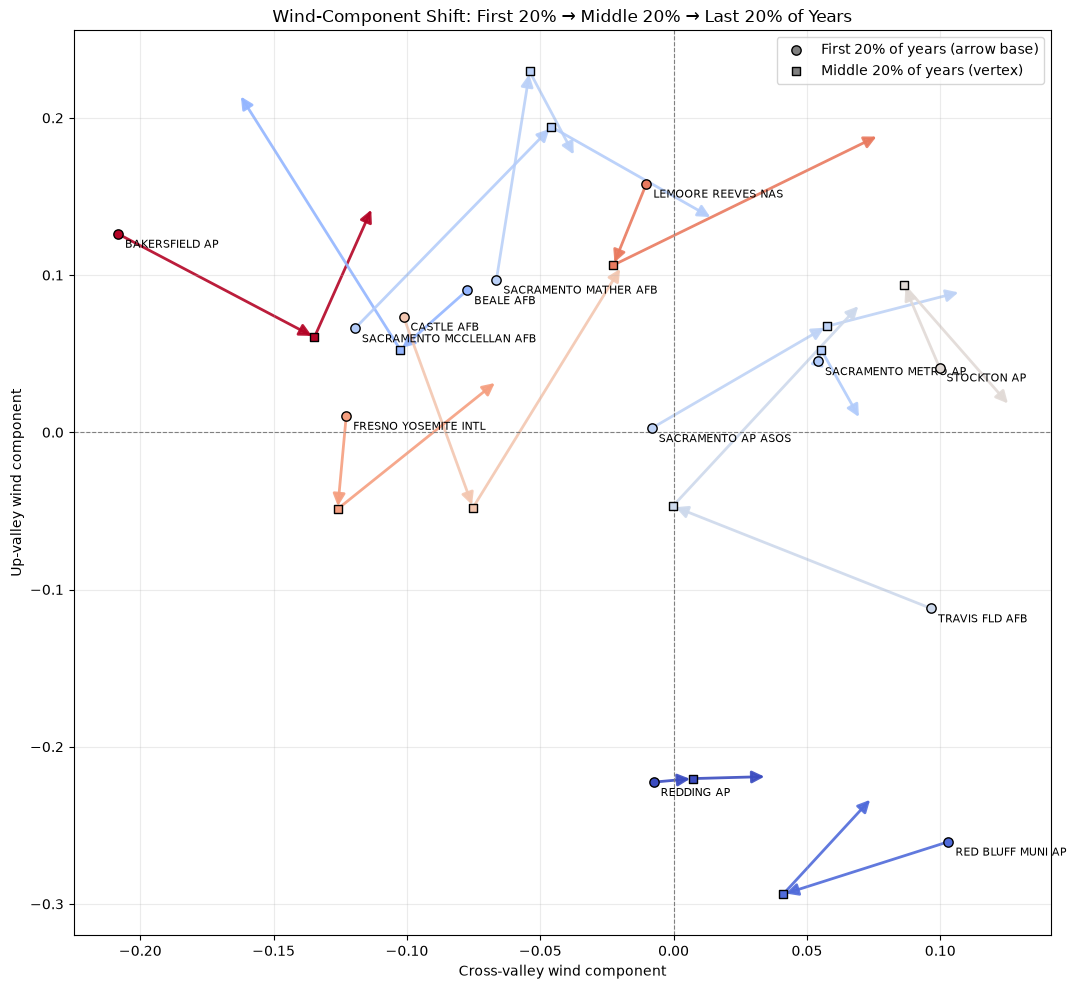

,STATION,first_x,first_y,middle_x,middle_y,last_x,last_y,latitude,first_years,middle_years,last_years
0,BAKERSFIELD AP,-0.208319,0.126216,-0.134691,0.060481,-0.112941,0.143177,35.4342,1932–1952,1970–1988,2007–2025
1,BEALE AFB,-0.077388,0.090341,-0.102516,0.052569,-0.162813,0.215061,39.1333,1960–1969,1982–1991,2016–2025
2,CASTLE AFB,-0.101261,0.073514,-0.075207,-0.047892,-0.019509,0.105471,37.3833,1942–1956,1968–1982,2009–2022
3,FRESNO YOSEMITE INTL,-0.122755,0.010400,-0.125968,-0.048796,-0.066238,0.032469,36.7800,1942–1962,1978–1993,2010–2025
4,LEMOORE REEVES NAS,-0.010201,0.158107,-0.022585,0.106357,0.077027,0.188891,36.3333,1962–1971,1982–1992,2012–2025
5,RED BLUFF MUNI AP,0.103079,-0.260431,0.041031,-0.293915,0.074400,-0.232474,40.1519,1946–1960,1976–1993,2009–2024
6,REDDING AP,-0.007467,-0.222530,0.007215,-0.220278,0.035119,-0.218978,40.5147,1974–1984,1994–2004,2015–2025
7,SACRAMENTO AP ASOS,-0.008184,0.002593,0.057455,0.067419,0.107811,0.089445,38.5067,1932–1956,1973–1990,2008–2025
8,SACRAMENTO MATHER AFB,-0.066447,0.097021,-0.053981,0.229514,-0.036956,0.175115,38.5667,1942–1957,1973–1987,2010–2025
9,SACRAMENTO MCCLELLAN AFB,-0.119483,0.066090,-0.045787,0.194282,0.014687,0.136022,38.6667,1940–1953,1966–1981,1995–2025


In [33]:
# Wind-component shift chain per station:
# first 20% of years -> middle 20% of years -> last 20% of years
# Circle = first 20% mean (chain start); square = middle 20% mean (vertex)

fig, ax = plt.subplots(figsize=(11, 10))
arrow_rows_3period = []

for station, group in annual_avg_wind.groupby("STATION"):
    group = (
        group[
            [
                "STATION",
                "year",
                "mean_up_valley_component",
                "mean_cross_valley_component",
                "latitude",
            ]
        ]
        .dropna()
        .sort_values("year")
    )

    if len(group) < 3:
        continue

    n_periods = max(1, int(np.ceil(len(group) * 0.20)))

    first_period = group.iloc[:n_periods]
    last_period = group.iloc[-n_periods:]

    # Center the middle 20% window around the midpoint of the record
    mid_start = (len(group) - n_periods) // 2
    middle_period = group.iloc[mid_start:mid_start + n_periods]

    arrow_rows_3period.append({
        "STATION": station,
        "first_x": first_period["mean_cross_valley_component"].mean(),
        "first_y": first_period["mean_up_valley_component"].mean(),
        "middle_x": middle_period["mean_cross_valley_component"].mean(),
        "middle_y": middle_period["mean_up_valley_component"].mean(),
        "last_x": last_period["mean_cross_valley_component"].mean(),
        "last_y": last_period["mean_up_valley_component"].mean(),
        "latitude": group["latitude"].iloc[0],
        "first_years": f"{first_period['year'].min()}–{first_period['year'].max()}",
        "middle_years": f"{middle_period['year'].min()}–{middle_period['year'].max()}",
        "last_years": f"{last_period['year'].min()}–{last_period['year'].max()}",
    })

arrow_df_3period = pd.DataFrame(arrow_rows_3period)

lat_min = arrow_df_3period["latitude"].min()
lat_range = arrow_df_3period["latitude"].max() - lat_min
lat_range = lat_range if lat_range != 0 else 1

for _, row in arrow_df_3period.iterrows():
    color = plt.cm.coolwarm_r((row["latitude"] - lat_min) / lat_range)

    # Arrow 1: first 20% -> middle 20%
    ax.add_patch(
        FancyArrowPatch(
            (row["first_x"], row["first_y"]),
            (row["middle_x"], row["middle_y"]),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2,
            color=color,
            alpha=0.9,
        )
    )

    # Arrow 2: middle 20% -> last 20%
    ax.add_patch(
        FancyArrowPatch(
            (row["middle_x"], row["middle_y"]),
            (row["last_x"], row["last_y"]),
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=2,
            color=color,
            alpha=0.9,
        )
    )

    # Mark the first-20% mean (chain start)
    ax.scatter(
        row["first_x"],
        row["first_y"],
        color=color,
        edgecolor="black",
        marker="o",
        s=45,
        zorder=3,
    )

    # Mark the middle-20% mean (chain vertex)
    ax.scatter(
        row["middle_x"],
        row["middle_y"],
        color=color,
        edgecolor="black",
        marker="s",
        s=35,
        zorder=3,
    )

    ax.annotate(
        row["STATION"],
        (row["first_x"], row["first_y"]),
        xytext=(5, -10),
        textcoords="offset points",
        fontsize=8,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)

# Legend for period markers
ax.scatter([], [], color="gray", edgecolor="black", marker="o", s=45,
           label="First 20% of years (arrow base)")
ax.scatter([], [], color="gray", edgecolor="black", marker="s", s=35,
           label="Middle 20% of years (vertex)")

ax.set_xlabel("Cross-valley wind component")
ax.set_ylabel("Up-valley wind component")
ax.set_title(
    "Wind-Component Shift: First 20% → Middle 20% → Last 20% of Years"
)
ax.grid(True, alpha=0.25)
ax.legend(loc="best")

plt.tight_layout()
plt.show()

display(arrow_df_3period)

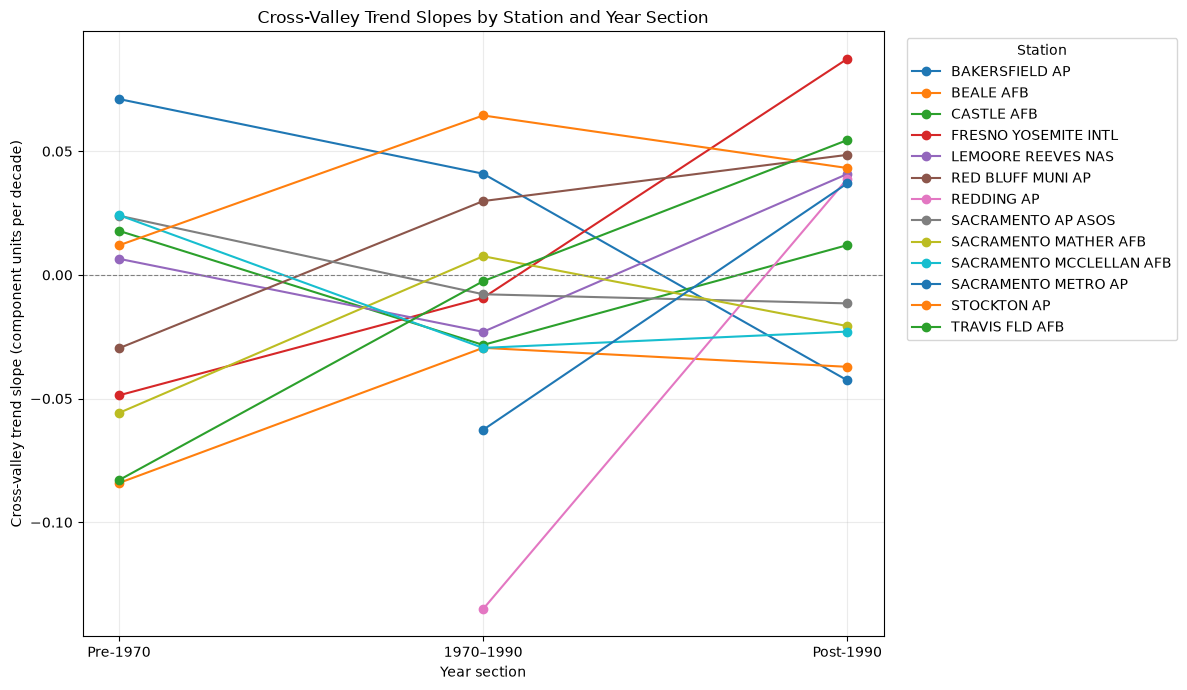

period,Pre-1970,1970–1990,Post-1990
STATION,,,
BAKERSFIELD AP,0.071107,0.040915,-0.042625
BEALE AFB,-0.084123,-0.029478,-0.037157
CASTLE AFB,0.017817,-0.028304,0.012046
FRESNO YOSEMITE INTL,-0.048680,-0.009251,0.087361
LEMOORE REEVES NAS,0.006516,-0.023006,0.040801
RED BLUFF MUNI AP,-0.029634,0.029862,0.048540
REDDING AP,NaN,-0.135062,0.038863
SACRAMENTO AP ASOS,0.023946,-0.007819,-0.011505
SACRAMENTO MATHER AFB,-0.055785,0.007562,-0.020684


In [34]:
periods = {
    "Pre-1970": (None, 1970),       # years < 1970
    "1970–1990": (1970, 1991),     # 1970 through 1990
    "Post-1990": (1991, None),      # years > 1990
}

slope_rows = []

for station, station_data in annual_event_wind.groupby("STATION"):
    for period, (start_year, end_year) in periods.items():
        data = station_data[["year", "mean_cross_valley_component"]].dropna()

        if start_year is not None:
            data = data[data["year"] >= start_year]
        if end_year is not None:
            data = data[data["year"] < end_year]

        if len(data) < 3 or data["year"].nunique() < 3:
            continue

        fit = stats.linregress(
            data["year"].to_numpy(),
            data["mean_cross_valley_component"].to_numpy()
        )

        slope_rows.append({
            "STATION": station,
            "period": period,
            "slope_per_decade": fit.slope * 10,
            "n_years": data["year"].nunique(),
        })

period_slopes = pd.DataFrame(slope_rows)

period_order = list(periods)
fig, ax = plt.subplots(figsize=(12, 7))

for station, data in period_slopes.groupby("STATION"):
    data = data.set_index("period").reindex(period_order).reset_index()
    ax.plot(
        data["period"],
        data["slope_per_decade"],
        marker="o",
        linewidth=1.5,
        label=station,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Year section")
ax.set_ylabel("Cross-valley trend slope (component units per decade)")
ax.set_title("Cross-Valley Trend Slopes by Station and Year Section")
ax.grid(True, alpha=0.25)
ax.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(
    period_slopes.pivot(
        index="STATION",
        columns="period",
        values="slope_per_decade"
    ).reindex(columns=period_order)
)

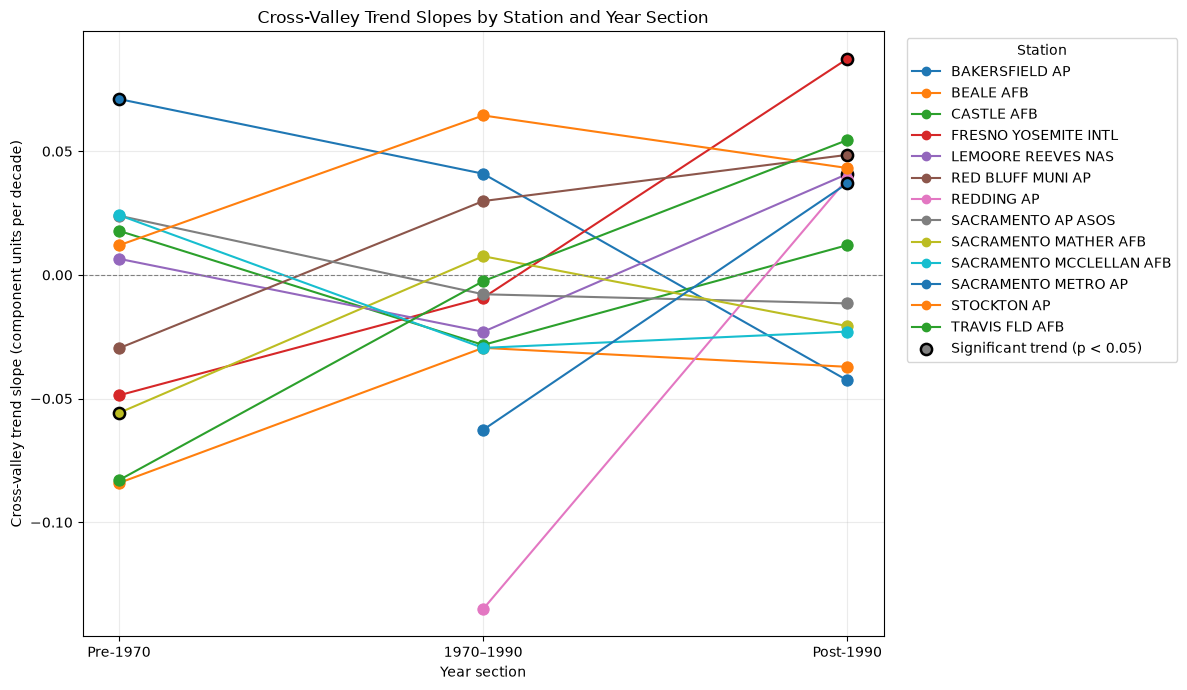

period,Pre-1970,1970–1990,Post-1990
STATION,,,
BAKERSFIELD AP,0.071107,0.040915,-0.042625
BEALE AFB,-0.084123,-0.029478,-0.037157
CASTLE AFB,0.017817,-0.028304,0.012046
FRESNO YOSEMITE INTL,-0.048680,-0.009251,0.087361
LEMOORE REEVES NAS,0.006516,-0.023006,0.040801
RED BLUFF MUNI AP,-0.029634,0.029862,0.048540
REDDING AP,NaN,-0.135062,0.038863
SACRAMENTO AP ASOS,0.023946,-0.007819,-0.011505
SACRAMENTO MATHER AFB,-0.055785,0.007562,-0.020684


In [35]:
periods = {
    "Pre-1970": (None, 1970),
    "1970–1990": (1970, 1991),
    "Post-1990": (1991, None),
}

slope_rows = []

for station, station_data in annual_event_wind.groupby("STATION"):
    for period, (start_year, end_year) in periods.items():
        data = station_data[["year", "mean_cross_valley_component"]].dropna()

        if start_year is not None:
            data = data[data["year"] >= start_year]
        if end_year is not None:
            data = data[data["year"] < end_year]

        if data["year"].nunique() < 3:
            continue

        fit = stats.linregress(
            data["year"].to_numpy(),
            data["mean_cross_valley_component"].to_numpy()
        )

        slope_rows.append({
            "STATION": station,
            "period": period,
            "slope_per_decade": fit.slope * 10,
            "p_value": fit.pvalue,
            "n_years": data["year"].nunique(),
        })

period_slopes = pd.DataFrame(slope_rows)
period_order = list(periods)

fig, ax = plt.subplots(figsize=(12, 7))

for station, data in period_slopes.groupby("STATION"):
    data = data.set_index("period").reindex(period_order).reset_index()

    line, = ax.plot(
        data["period"],
        data["slope_per_decade"],
        marker="o",
        linewidth=1.5,
        label=station,
    )
    color = line.get_color()

    for _, point in data.dropna(subset=["slope_per_decade"]).iterrows():
        significant = point["p_value"] < 0.05
        ax.scatter(
            point["period"],
            point["slope_per_decade"],
            s=65,
            facecolor=color,
            edgecolor="black" if significant else color,
            linewidth=1.8 if significant else 0.8,
            zorder=3,
        )

ax.scatter(
    [], [], s=65, facecolor="gray", edgecolor="black",
    linewidth=1.8, label="Significant trend (p < 0.05)"
)

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Year section")
ax.set_ylabel("Cross-valley trend slope (component units per decade)")
ax.set_title("Cross-Valley Trend Slopes by Station and Year Section")
ax.grid(True, alpha=0.25)
ax.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(
    period_slopes.pivot(
        index="STATION",
        columns="period",
        values="slope_per_decade"
    ).reindex(columns=period_order)
)

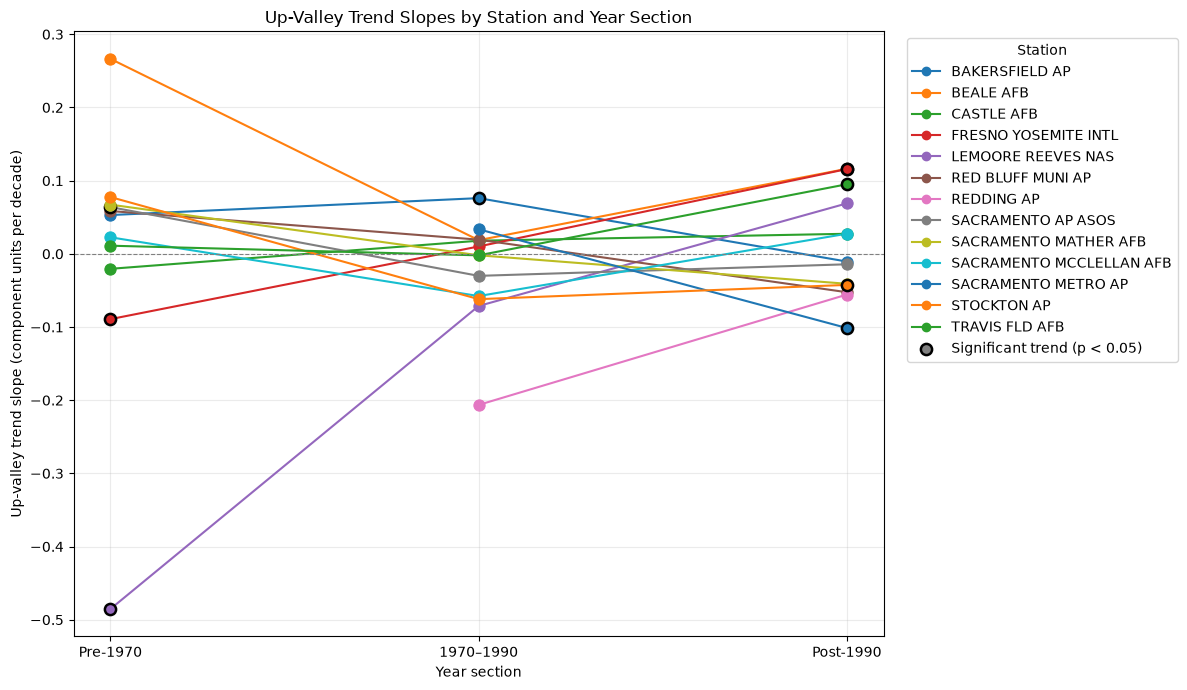

period,Pre-1970,1970–1990,Post-1990
STATION,,,
BAKERSFIELD AP,0.052977,0.076102,-0.010552
BEALE AFB,0.266432,0.018676,0.116185
CASTLE AFB,-0.020484,0.017901,0.027410
FRESNO YOSEMITE INTL,-0.089234,0.010075,0.115839
LEMOORE REEVES NAS,-0.485285,-0.071271,0.068931
RED BLUFF MUNI AP,0.058504,0.019349,-0.052477
REDDING AP,NaN,-0.206438,-0.055657
SACRAMENTO AP ASOS,0.063878,-0.030104,-0.014283
SACRAMENTO MATHER AFB,0.067224,-0.001966,-0.040920


In [36]:
# Same plot as the previous cell, using up-valley components.

slope_rows_up = []

for station, station_data in annual_event_wind.groupby("STATION"):
    for period, (start_year, end_year) in periods.items():
        data = station_data[["year", "mean_up_valley_component"]].dropna()

        if start_year is not None:
            data = data[data["year"] >= start_year]
        if end_year is not None:
            data = data[data["year"] < end_year]

        if data["year"].nunique() < 3:
            continue

        fit = stats.linregress(
            data["year"].to_numpy(),
            data["mean_up_valley_component"].to_numpy()
        )

        slope_rows_up.append({
            "STATION": station,
            "period": period,
            "slope_per_decade": fit.slope * 10,
            "p_value": fit.pvalue,
            "n_years": data["year"].nunique(),
        })

period_slopes_up = pd.DataFrame(slope_rows_up)
period_order = list(periods)

fig, ax = plt.subplots(figsize=(12, 7))

for station, data in period_slopes_up.groupby("STATION"):
    data = data.set_index("period").reindex(period_order).reset_index()

    line, = ax.plot(
        data["period"],
        data["slope_per_decade"],
        marker="o",
        linewidth=1.5,
        label=station,
    )
    color = line.get_color()

    for _, point in data.dropna(subset=["slope_per_decade"]).iterrows():
        significant = point["p_value"] < 0.05
        ax.scatter(
            point["period"],
            point["slope_per_decade"],
            s=65,
            facecolor=color,
            edgecolor="black" if significant else color,
            linewidth=1.8 if significant else 0.8,
            zorder=3,
        )

ax.scatter(
    [], [], s=65, facecolor="gray", edgecolor="black",
    linewidth=1.8, label="Significant trend (p < 0.05)"
)

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("Year section")
ax.set_ylabel("Up-valley trend slope (component units per decade)")
ax.set_title("Up-Valley Trend Slopes by Station and Year Section")
ax.grid(True, alpha=0.25)
ax.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(
    period_slopes_up.pivot(
        index="STATION",
        columns="period",
        values="slope_per_decade"
    ).reindex(columns=period_order)
)